# SilenceCut — исследование обнаружения неречевых фрагментов

Исследовательский notebook для ВКР. Сравниваются энергетический RMS, нейросетевой Silero VAD, временные сегменты Whisper и собственный Spectral VAD на энергии, энтропии и плоскостности спектра.

**Два набора данных выполняют разные задачи.** Исходное test_video.mp4 используется для первичного исследования и подготовки ручной разметки. KAIST VAD предоставляет эталонную разметку для численной оценки. Их результаты и временные шкалы не смешиваются.

**Для просмотра и защиты:** готовые результаты уже сохранены в выводах. Чтобы заново получить итоговые таблицы и графики, перезапустите ядро и выполните только **раздел 10**, начиная с его ячейки загрузки. Он не требует CUDA, модели Whisper или исходных WAV/MAT и ничего не записывает в results/.

**Для повторения вычислительных экспериментов:** выберите существующее окружение backend/venv и выполняйте разделы по порядку. Разделы 3–5 заново обрабатывают исходное видео, а 6–8 выполняют подбор и эксперименты KAIST и сохраняют результаты. Для повторения нужны исходные медиа, ML-зависимости и NVIDIA CUDA для текущей конфигурации Whisper. Исторические выводы и исходные параметры сохранены; счётчики выполнения относятся к разным прежним запускам.

1. [Подготовка и воспроизводимость](#preparation)
2. [Данные и Ground Truth](#data)
3. [RMS](#rms)
4. [Silero VAD](#silero)
5. [Whisper](#whisper)
6. [Собственный Spectral VAD](#spectral)
7. [Подбор параметров](#tuning)
8. [Оценка по Ground Truth](#evaluation)
9. [Первичные сравнения и сохранённые наблюдения](#comparisons)
10. [Итоговое сравнение методов на KAIST VAD и выводы](#kaist-final)

<a id="preparation"></a>
## 1. Подготовка и воспроизводимость

Перед будущим вычислительным запуском задаём **seed = 42** для `random`, NumPy и PyTorch, если он установлен. Дополнительно задаём seed CTranslate2: именно этот движок выполняет декодирование Faster-Whisper и использует собственный генератор случайных чисел. Выполнение ячейки с seed не запускает распознавание, RMS или VAD.

Seed старых CSV **не был зафиксирован**. Настройка 42 относится к новым экспериментам и не меняет уже сохранённые результаты. Для работы с ними используем CSV и metadata. Одинаковый seed не гарантирует побитовое совпадение на других версиях библиотек и оборудовании.

В `results/experiment_metadata.json` записаны версии Python и библиотек, ОС, CPU/GPU, SHA-256 видео, параметры методов и результаты статического анализа вариативности Whisper. [Seed CTranslate2](https://opennmt.net/CTranslate2/python/ctranslate2.set_random_seed.html).

Устанавливаем seed до вычислительных запусков. PyTorch используется только если установлен; настройка seed не запускает модели.

In [1]:
import random
import importlib.util

import numpy as np
import ctranslate2

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
ctranslate2.set_random_seed(SEED)

seed_applied = {"random": True, "numpy": True, "ctranslate2": True, "torch": False}
if importlib.util.find_spec("torch") is not None:
    import torch
    torch.manual_seed(SEED)
    seed_applied["torch"] = True

print(f"Seed для будущих запусков: {SEED}")
print("Генераторы:", seed_applied)
if not seed_applied["torch"]:
    print("PyTorch не установлен: его seed пропущен.")

Seed для будущих запусков: 42
Генераторы: {'random': True, 'numpy': True, 'ctranslate2': True, 'torch': False}
PyTorch не установлен: его seed пропущен.


Читаем сохранённую среду исходного эксперимента: версии, оборудование, SHA-256 и параметры Whisper. Это историческая среда, а не автоматическое описание текущего компьютера.

In [2]:
import json
from pathlib import Path

import pandas as pd

repro_results_dir = Path("results")
if not (repro_results_dir / "experiment_metadata.json").is_file():
    repro_results_dir = Path("backend") / "results"
repro_metadata = json.loads((repro_results_dir / "experiment_metadata.json").read_text(encoding="utf-8"))

print("ОС:", repro_metadata["environment"]["os"]["caption"])
print("CPU:", repro_metadata["environment"]["cpu"]["model"])
print("GPU:", repro_metadata["environment"]["gpu"][0]["model"])
print("SHA-256 видео:", repro_metadata["source"]["sha256"])
print("Seed сохранённых CSV:", repro_metadata["reproducibility"]["existing_csv_seed_status"])
print("Аргументов Whisper transcribe:", len(repro_metadata["methods"]["whisper"]["parameters"]["transcribe_call_arguments"]))

pd.DataFrame(
    {"package": package, "version": repro_metadata["versions"].get(package)}
    for package in ["python", "faster-whisper", "ctranslate2", "numpy", "pandas", "torch", "onnxruntime"]
)

ОС: Майкрософт Windows 11 Pro
CPU: AMD Ryzen 7 7800X3D 8-Core Processor
GPU: NVIDIA GeForce RTX 3070
SHA-256 видео: 77e46a42708d73daa9bff1351a509820cbf48c914310670489da4022b5fc554b
Seed сохранённых CSV: not recorded at generation time
Аргументов Whisper transcribe: 35


,package,version
0,python,3.11.9
1,faster-whisper,1.2.1
2,ctranslate2,4.8.2
3,numpy,2.4.6
4,pandas,3.0.6
5,torch,NaN
6,onnxruntime,1.29.0


### 1.1. Историческая вариативность сегментов Whisper

В обоих сохранённых сценариях код задаёт `small`, `cuda`, `float16`, русский язык и отключённый VAD. В metadata зафиксирован набор температур `[0, 0.2, 0.4, 0.6, 0.8, 1.0]`. В установленном коде `generate_with_fallback` при `compression_ratio > 2.4` или `avg_logprob < −1.0` возможен переход к следующей температуре. При температуре выше нуля включается **случайная выборка токенов**, а не beam search с исходной шириной 5.

Сгенерированные токены временных меток определяют разбиение на сегменты и продвижение по аудио. При `condition_on_previous_text=True` предыдущий текст влияет на следующие окна, поэтому изменения могут распространяться на продолжение записи. Незафиксированный seed CTranslate2 — правдоподобный источник различий. Seed Python, NumPy или PyTorch сам по себе не задаёт seed этого движка.

Это **гипотеза по коду**, а не доказанная причина конкретных запусков. В CSV нет температур по сегментам, вероятностей и логов fallback; полный результат запуска на 165 сегментов не сохранён. Версии текущего окружения совпадают с metadata зафиксированного запуска (`faster-whisper 1.2.1`, `ctranslate2 4.8.2`), но отдельного снимка версий старого запуска нет. Оснований утверждать, что причиной стало обновление библиотек, недостаточно.

Для воспроизведения текущих сравнений используются сохранённые CSV. При будущих вычислительных экспериментах seed-ячейка выполняется до создания модели; параметры и диагностические показатели каждого запуска следует сохранять отдельно.

<a id="data"></a>
## 2. Данные и Ground Truth

| Источник | Назначение | Эталон |
|---|---|---|
| backend/test_video.mp4 | Первичные опыты RMS, Silero и Whisper на русской записи | Пять выбранных фрагментов ещё не являются готовой ручной разметкой |
| backend/.cache/kaist_vad/record_data/*.wav | Настройка и тестирование на KAIST | Бинарный y_label из одноимённых MAT: один элемент на аудиосэмпл |
| results/kaist_spectral_vad/ | Подбор Spectral, его полные тесты и отдельный клип 280–340 с | Зафиксированные интервалы KAIST |
| results/kaist_full_comparison/ | Полные тесты четырёх методов на трёх WAV | Те же эталонные MAT |

На KAIST construction_site.wav — единственная настроечная запись. room.wav, park.wav, bus_stop.wav — тестовые. Разделение сделано по записям и условиям, но не по дикторам. Данные доступны из [Recorded Dataset KAIST VAD](https://github.com/jtkim-kaist/VAD#recorded-dataset); загрузка и прослушивание вынесены в kaist_vad_preview.ipynb.

Следующая ячейка показывает наличие файлов и длительности из сохранённого эксперимента. Отсутствие локальных WAV/MAT не мешает чтению итогового раздела при наличии CSV/JSON.

In [2]:
from pathlib import Path
import pandas as pd
from IPython.display import display

data_backend = next((p.resolve() for p in (Path.cwd(), Path.cwd() / "backend") if (p / "test_venv.ipynb").is_file()), None)
if data_backend is None:
    raise FileNotFoundError("Откройте notebook из backend/ или корня проекта.")
data_spectral = pd.read_csv(data_backend / "results/kaist_spectral_vad/spectral_recording_metrics.csv", float_precision="round_trip")
data_rows = []
for data_name in ["construction_site", "room", "park", "bus_stop"]:
    data_row = data_spectral.loc[data_spectral["recording"] == data_name].iloc[0]
    data_rows.append({
        "Запись": data_name + ".wav",
        "Назначение": "Подбор" if data_row["split"] == "tuning" else "Тест",
        "Длительность, с": data_row["duration_s"],
        "WAV доступен": (data_backend / f".cache/kaist_vad/record_data/{data_name}.wav").is_file(),
        "MAT доступен": (data_backend / f".cache/kaist_vad/record_data/{data_name}.mat").is_file(),
    })
display(pd.DataFrame(data_rows).round({"Длительность, с": 3}))
print("Исходное видео доступно:", (data_backend / "test_video.mp4").is_file())

,Запись,Назначение,"Длительность, с",WAV доступен,MAT доступен
0,construction_site.wav,Подбор,1801.660,True,True
1,room.wav,Тест,1802.519,True,True
2,park.wav,Тест,1804.028,True,True
3,bus_stop.wav,Тест,1801.497,True,True


Исходное видео доступно: True


### 2.1. Исходное видео: выбор фрагментов для будущей ручной разметки

На этом этапе выбираем **пять непересекающихся фрагментов по 60 секунд** из разных частей видео. Это список участков для будущего прослушивания и ручной разметки, а не готовый Ground Truth. Истинные границы речи пока не задаём, видео не обрезаем.

Следующие три Code-ячейки работают самостоятельно после перезапуска ядра: они читают только сохранённые CSV и JSON из `results/`. Запускать предыдущие вычислительные разделы Whisper, RMS и Silero не требуется. RMS используется при ранее сохранённом пороге **−40 dBFS**.

Рассматриваем окна длительностью 60 секунд с шагом 10 секунд. По середине окна относим их к одной из пяти равных частей полной записи. В каждой части выбираем свой диагностический случай: небольшое расхождение; крупные промежутки без распознанной речи Whisper; близкая суммарная неречь RMS и Silero; длинная пауза Silero при сплошной речи Whisper; почти непрерывная речь по RMS в конце записи.

Неречь каждого метода считаем по его `silence_intervals.csv`, обрезая интервалы по границам окна. **Попарное расхождение** — время, когда один метод считает момент речью, а другой неречью (симметрическая разность интервалов). **Общее расхождение** — время, когда хотя бы один из трёх методов отличается от остальных; его процент считаем от 60 секунд. Для трёх бинарных решений это половина суммы трёх попарных расхождений. Расчёт ведём по точным границам CSV, без дискретизации времени; округление используется только при выводе.


Загружаем замороженные результаты исходного видео и определяем функции расчёта расхождений. Разметка KAIST здесь не создаётся.

Длительность пересечения двух упорядоченных наборов интервалов.

In [1]:
import hashlib
import json
import math
from pathlib import Path

import pandas as pd
from IPython.display import display

gt_results_dir = Path("results")
if not (gt_results_dir / "experiment_metadata.json").is_file():
    gt_results_dir = Path("backend") / "results"
gt_results_dir = gt_results_dir.resolve()
gt_metadata_path = gt_results_dir / "experiment_metadata.json"
gt_metadata = json.loads(gt_metadata_path.read_text(encoding="utf-8"))
gt_video_duration = gt_metadata["source"]["audio_duration_seconds"]
assert gt_metadata["interval_convention"] == "[start, end)"
assert gt_metadata["methods"]["rms"]["parameters"]["threshold_dbfs"] == -40

gt_silence_intervals = {}
gt_source_hashes = {
    gt_metadata_path: hashlib.sha256(gt_metadata_path.read_bytes()).hexdigest()
}
for method in ["whisper", "rms", "silero"]:
    filename = f"{method}_silence_intervals.csv"
    path = gt_results_dir / filename
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest == gt_metadata["csv_files"][filename]["sha256"], filename
    gt_source_hashes[path] = digest
    table = pd.read_csv(path, float_precision="round_trip")
    assert table.columns.tolist() == ["start", "end"]
    intervals = list(table.itertuples(index=False, name=None))
    previous_end = 0.0
    for start, end in intervals:
        assert math.isfinite(start) and math.isfinite(end)
        assert 0 <= start < end <= gt_video_duration + 1e-9
        assert start >= previous_end - 1e-9
        previous_end = end
    gt_silence_intervals[method] = intervals


def gt_clip_intervals(intervals, start, end):
    return [
        (max(start, a), min(end, b))
        for a, b in intervals if a < end and b > start
    ]


def gt_intersection_seconds(left, right):

    i = j = 0
    total = 0.0
    while i < len(left) and j < len(right):
        total += max(0.0, min(left[i][1], right[j][1]) - max(left[i][0], right[j][0]))
        if left[i][1] <= right[j][1]:
            i += 1
        else:
            j += 1
    return total


def gt_window_metrics(start, end):
    clipped = {
        method: gt_clip_intervals(intervals, start, end)
        for method, intervals in gt_silence_intervals.items()
    }
    row = {"start": float(start), "end": float(end), "duration": float(end - start)}
    for method, intervals in clipped.items():
        durations = [b - a for a, b in intervals]
        row[f"{method}_non_speech_s"] = sum(durations, 0.0)
        row[f"{method}_pause_count"] = len(durations)
        row[f"{method}_max_pause_s"] = max(durations, default=0.0)
    pairwise = []
    for left, right in [("whisper", "rms"), ("whisper", "silero"), ("rms", "silero")]:
        difference = (
            row[f"{left}_non_speech_s"] + row[f"{right}_non_speech_s"]
            - 2 * gt_intersection_seconds(clipped[left], clipped[right])
        )
        row[f"{left}_{right}_disagreement_s"] = max(0.0, difference)
        pairwise.append(max(0.0, difference))
    row["disagreement_s"] = sum(pairwise) / 2
    row["disagreement_percent"] = 100 * row["disagreement_s"] / row["duration"]
    return row


print(f"Загружены сохранённые интервалы; длительность аудио: {gt_video_duration:.3f} с.")

Загружены сохранённые интервалы; длительность аудио: 1428.956 с.


Выбираем пять диагностических фрагментов исходного видео. Этот целевой отбор не используется как тестовая выборка KAIST.

Разные критерии дают и спокойный участок, и сложные случаи для проверки.

In [2]:
gt_window_seconds = 60
gt_step_seconds = 10
gt_candidate_rows = []
for start in range(0, int(gt_video_duration - gt_window_seconds) + 1, gt_step_seconds):
    end = start + gt_window_seconds
    row = gt_window_metrics(start, end)
    row["zone"] = min(5, int(((start + end) / 2) / gt_video_duration * 5) + 1)
    row["rms_silero_total_gap_s"] = abs(row["rms_non_speech_s"] - row["silero_non_speech_s"])
    gt_candidate_rows.append(row)
gt_candidates = pd.DataFrame(gt_candidate_rows)


def gt_zone_candidates(zone):
    return gt_candidates[gt_candidates["zone"] == zone]



gt_beginning = gt_zone_candidates(1).nsmallest(1, "disagreement_s")
gt_whisper_gap = gt_zone_candidates(2).sort_values(
    ["whisper_non_speech_s", "disagreement_s", "start"], ascending=[False, False, True]
).head(1)
gt_similar_totals = gt_zone_candidates(3).nsmallest(1, "rms_silero_total_gap_s")

gt_longest_silero_pause = max(gt_silence_intervals["silero"], key=lambda interval: interval[1] - interval[0])
gt_zone_four = gt_zone_candidates(4)
gt_long_pause_candidates = gt_zone_four[
    (gt_zone_four["start"] <= gt_longest_silero_pause[0])
    & (gt_zone_four["end"] >= gt_longest_silero_pause[1])
    & (gt_zone_four["whisper_non_speech_s"] < 1e-9)
]
assert not gt_long_pause_candidates.empty
gt_long_pause = gt_long_pause_candidates.sort_values(
    ["silero_non_speech_s", "start"], ascending=[False, True]
).head(1)
gt_ending = gt_zone_candidates(5).nsmallest(1, "rms_non_speech_s")

gt_selected_metrics = pd.concat(
    [gt_beginning, gt_whisper_gap, gt_similar_totals, gt_long_pause, gt_ending],
    ignore_index=True,
).drop(columns=["zone", "rms_silero_total_gap_s"])
gt_profiles = [
    "Малое расхождение в начале", "Крупные промежутки Whisper", "Близкие суммы, разные границы",
    "Длинная пауза Silero", "Почти сплошная речь RMS в конце",
]
gt_reasons = [
    f"Начало записи: минимальное общее расхождение среди окон первой части. Silero выделяет {int(gt_selected_metrics.loc[0, 'silero_pause_count'])} пауз; самая длинная — {gt_selected_metrics.loc[0, 'silero_max_pause_s']:.3f} с. Участок для проверки относительно согласованных решений.",
    "Вторая часть записи: максимальная суммарная неречь Whisper; при равенстве выбран участок с большим расхождением. В него входят промежутки Whisper 318–327 и 332–357 с, которые предстоит проверить прослушиванием.",
    f"Середина записи: наиболее близкая суммарная неречь RMS и Silero среди окон третьей части, но их временные решения различаются на {gt_selected_metrics.loc[2, 'rms_silero_disagreement_s']:.3f} с. RMS даёт {int(gt_selected_metrics.loc[2, 'rms_pause_count'])} коротких промежутков, Silero — {int(gt_selected_metrics.loc[2, 'silero_pause_count'])} пауз.",
    f"Четвёртая часть: целиком включает самый длинный неречевой интервал Silero {gt_longest_silero_pause[0]:.3f}–{gt_longest_silero_pause[1]:.3f} с ({gt_longest_silero_pause[1]-gt_longest_silero_pause[0]:.3f} с). Whisper считает всё окно речью. Среди таких окон выбрана максимальная суммарная неречь Silero.",
    f"Конец записи: минимальная неречь RMS среди окон пятой части. При этом Silero выделяет {int(gt_selected_metrics.loc[4, 'silero_pause_count'])} пауз; максимальная — {gt_selected_metrics.loc[4, 'silero_max_pause_s']:.3f} с. Проверяем расхождение уровня сигнала и VAD.",
]

ground_truth_segments = gt_selected_metrics.copy()
ground_truth_segments.insert(0, "segment_id", [f"segment_{i:02d}" for i in range(1, 6)])
ground_truth_segments.insert(4, "selection_profile", gt_profiles)
ground_truth_segments.insert(5, "reason", gt_reasons)
for method in ["whisper", "rms", "silero"]:
    ground_truth_segments[f"{method}_pause_count"] = ground_truth_segments[f"{method}_pause_count"].astype(int)

print(f"Рассмотрено {len(gt_candidates)} окон; выбрано 5 разных участков, всего 300 секунд.")
gt_summary_columns = [
    "segment_id", "start", "end", "whisper_non_speech_s", "rms_non_speech_s",
    "silero_non_speech_s", "disagreement_s", "disagreement_percent",
]
display(ground_truth_segments[gt_summary_columns].round(3))
print("Попарное временное расхождение, секунды:")
display(ground_truth_segments[[
    "segment_id", "whisper_rms_disagreement_s", "whisper_silero_disagreement_s", "rms_silero_disagreement_s"
]].round(3))
for row in ground_truth_segments.itertuples(index=False):
    print(f"\n{row.segment_id}: {row.start:.0f}–{row.end:.0f} с. {row.reason}")

Рассмотрено 137 окон; выбрано 5 разных участков, всего 300 секунд.


,segment_id,start,end,whisper_non_speech_s,rms_non_speech_s,silero_non_speech_s,disagreement_s,disagreement_percent
0,segment_01,130.0,190.0,1.0,3.09,3.904,6.524,10.873
1,segment_02,300.0,360.0,34.0,6.18,16.576,43.934,73.223
2,segment_03,680.0,740.0,3.0,10.10,10.208,16.502,27.503
3,segment_04,850.0,910.0,0.0,8.22,16.960,19.602,32.670
4,segment_05,1360.0,1420.0,0.0,0.85,13.696,14.062,23.437


Попарное временное расхождение, секунды:


,segment_id,whisper_rms_disagreement_s,whisper_silero_disagreement_s,rms_silero_disagreement_s
0,segment_01,3.85,4.200,4.998
1,segment_02,33.16,38.192,16.516
2,segment_03,11.64,8.880,12.484
3,segment_04,8.22,16.960,14.024
4,segment_05,0.85,13.696,13.578



segment_01: 130–190 с. Начало записи: минимальное общее расхождение среди окон первой части. Silero выделяет 6 пауз; самая длинная — 1.216 с. Участок для проверки относительно согласованных решений.

segment_02: 300–360 с. Вторая часть записи: максимальная суммарная неречь Whisper; при равенстве выбран участок с большим расхождением. В него входят промежутки Whisper 318–327 и 332–357 с, которые предстоит проверить прослушиванием.

segment_03: 680–740 с. Середина записи: наиболее близкая суммарная неречь RMS и Silero среди окон третьей части, но их временные решения различаются на 12.484 с. RMS даёт 164 коротких промежутков, Silero — 16 пауз.

segment_04: 850–910 с. Четвёртая часть: целиком включает самый длинный неречевой интервал Silero 877.568–881.408 с (3.840 с). Whisper считает всё окно речью. Среди таких окон выбрана максимальная суммарная неречь Silero.

segment_05: 1360–1420 с. Конец записи: минимальная неречь RMS среди окон пятой части. При этом Silero выделяет 18 пауз; максим

Проверяем границы и точное совпадение сохранённого CSV; файл создаётся только при отсутствии.

In [3]:
assert len(ground_truth_segments) == 5
assert (ground_truth_segments["duration"] == 60).all()
assert (ground_truth_segments["start"] >= 0).all()
assert (ground_truth_segments["end"] <= gt_video_duration).all()
assert (ground_truth_segments["start"].iloc[1:].to_numpy() >= ground_truth_segments["end"].iloc[:-1].to_numpy()).all()
assert ground_truth_segments["disagreement_s"].between(0, 60).all()

gt_output_path = gt_results_dir / "ground_truth_segments.csv"
if not gt_output_path.exists():
    ground_truth_segments.to_csv(gt_output_path, index=False, encoding="utf-8")
gt_reloaded = pd.read_csv(gt_output_path, encoding="utf-8", float_precision="round_trip", keep_default_na=False)
pd.testing.assert_frame_equal(ground_truth_segments, gt_reloaded, check_exact=True)

for path, digest in gt_source_hashes.items():
    assert hashlib.sha256(path.read_bytes()).hexdigest() == digest, f"Изменён исходный файл: {path.name}"
print(f"Список фрагментов сохранён: {gt_output_path}")
print("Повторная загрузка CSV совпадает точно. Исходные CSV и metadata не изменены.")
print("Это только список фрагментов: эталонные speech/silence интервалы ещё не размечены.")

Список фрагментов сохранён: Z:\polikek 7\videoeditor\backend\results\ground_truth_segments.csv
Повторная загрузка CSV совпадает точно. Исходные CSV и metadata не изменены.
Это только список фрагментов: эталонные speech/silence интервалы ещё не размечены.


### 2.2. Отбор фрагментов ещё не является Ground Truth

В `ground_truth_segments.csv` сохранены границы пяти фрагментов, причины выбора, длительности неречи по методам, попарные и общие расхождения, количество и максимальная длительность пауз внутри каждого окна. `start` / `end` — абсолютные секунды от начала аудио; на границе окна пауза учитывается только своей попавшей в окно частью.

Это целенаправленный отбор разных диагностических случаев, включая относительно согласованный участок. Он не является случайной выборкой для несмещённой оценки всей записи. До ручного прослушивания нельзя утверждать, что промежутки, отмеченные методами, действительно являются неречью, или выбирать лучший метод. Следующий этап — согласовать правила ручной разметки и обозначить истинные интервалы речи внутри этих пяти фрагментов; сейчас разметка не создаётся.


<a id="rms"></a>
## 3. RMS — энергетический baseline

RMS (root mean square) — среднеквадратический уровень аудиосигнала. Это простой baseline: делим аудио на короткие окна, измеряем их уровень и считаем окна ниже порога кандидатами на тишину.

Для окна из $N$ отсчётов: $RMS = \sqrt{\frac{1}{N}\sum_{i=1}^{N}x_i^2}$. Переводим уровень в $dBFS = 20\log_{10}(RMS)$ относительно амплитуды полной шкалы 1. Аудио загружается как mono PCM, 16 кГц, с исходным уровнем громкости; нормализацию по пику не применяем. Окна по 30 мс не перекрываются. Последнее короткое окно учитывается по фактическим отсчётам.

Сравним пороги −50, −45, −40, −35 и −30 dBFS. Более высокий порог относит больше окон к тишине, но может захватить тихую речь. Соседние окна одной категории объединяем в интервалы; короткие провалы сохраняем без сглаживания. В отличие от таблицы Whisper, здесь учитываем также тишину в начале и конце аудио.

RMS оценивает энергию, поэтому участки выше порога — **предполагаемая речь**, которая может оказаться музыкой или шумом. Раздел можно выполнять отдельно, сверху вниз. Для загрузки используем уже установленный [декодер Faster-Whisper на PyAV](https://github.com/SYSTRAN/faster-whisper/blob/master/faster_whisper/audio.py); модель не загружается.

Декодируем исходное видео в mono 16 кГц без ML-модели и начинаем измерение времени.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from faster_whisper.audio import decode_audio

%matplotlib inline

rms_video_path = Path("test_video.mp4")
if not rms_video_path.is_file():
    rms_video_path = Path("backend") / "test_video.mp4"
rms_video_path = rms_video_path.resolve()
if not rms_video_path.is_file():
    raise FileNotFoundError(f"Видео не найдено: {rms_video_path}")

rms_sample_rate = 16000
rms_started_at = time.perf_counter()
rms_audio = decode_audio(str(rms_video_path), sampling_rate=rms_sample_rate)
if len(rms_audio) == 0:
    raise ValueError("Аудиодорожка пуста")
rms_audio_duration = len(rms_audio) / rms_sample_rate

print(f"Длительность аудио: {rms_audio_duration:.3f} сек.")
print(f"Частота дискретизации: {rms_sample_rate} Гц; каналов: 1")

Z:\polikek 7\videoeditor\backend\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Длительность аудио: 1428.956 сек.
Частота дискретизации: 16000 Гц; каналов: 1


Вычисляем RMS в окнах 30 мс; последнее окно учитывается по фактической длине.

Нулевой RMS ограничиваем снизу только для защиты от log10(0).

In [2]:
rms_window_ms = 30
rms_window_samples = round(rms_sample_rate * rms_window_ms / 1000)
rms_rows = []

for sample_start in range(0, len(rms_audio), rms_window_samples):
    sample_end = min(sample_start + rms_window_samples, len(rms_audio))
    window = rms_audio[sample_start:sample_end]
    rms_value = np.sqrt(np.mean(window ** 2, dtype=np.float64))
    rms_rows.append(
        {
            "start": sample_start / rms_sample_rate,
            "end": sample_end / rms_sample_rate,
            "rms": rms_value,
        }
    )

rms_windows_df = pd.DataFrame(rms_rows, columns=["start", "end", "rms"])

rms_windows_df["dbfs"] = 20 * np.log10(rms_windows_df["rms"].clip(lower=1e-10))
rms_elapsed = time.perf_counter() - rms_started_at

print(f"Размер окна: {rms_window_ms} мс; количество окон: {len(rms_windows_df)}")
print(f"Загрузка аудио и расчёт RMS: {rms_elapsed:.2f} сек.")
rms_windows_df.head()

Размер окна: 30 мс; количество окон: 47632


Загрузка аудио и расчёт RMS: 1.40 сек.


,start,end,rms,dbfs
0,0.00,0.03,0.000000,-200.000000
1,0.03,0.06,0.014565,-36.733684
2,0.06,0.09,0.031965,-29.906609
3,0.09,0.12,0.011916,-38.477049
4,0.12,0.15,0.009333,-40.599178


Показываем сигнал и исследуемые пороги; ограничение уровня на рисунке не меняет данные.

Ограничение -80 dBFS относится только к рисунку: исходные уровни сохраняются.

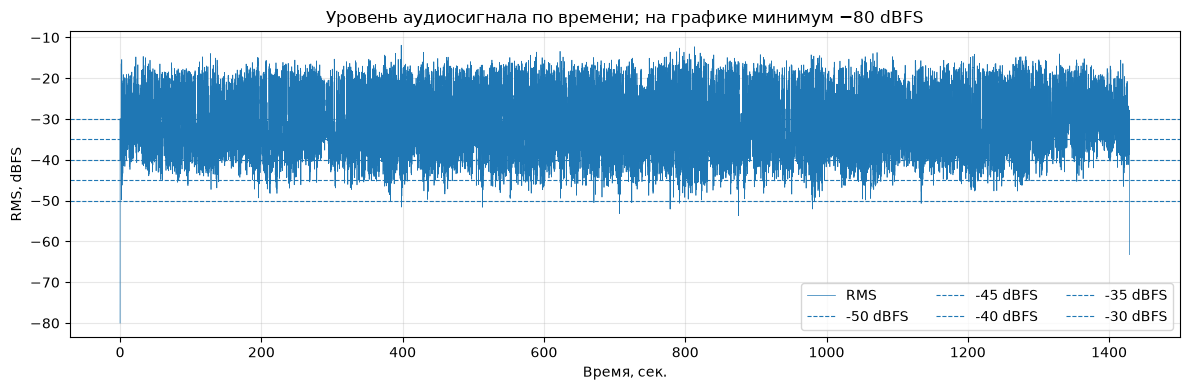

In [3]:
rms_thresholds_dbfs = [-50, -45, -40, -35, -30]

plt.figure(figsize=(12, 4))

plt.plot(rms_windows_df["start"], rms_windows_df["dbfs"].clip(lower=-80), linewidth=0.5, label="RMS")
for threshold in rms_thresholds_dbfs:
    plt.axhline(threshold, linestyle="--", linewidth=0.8, label=f"{threshold} dBFS")
plt.title("Уровень аудиосигнала по времени; на графике минимум −80 dBFS")
plt.xlabel("Время, сек.")
plt.ylabel("RMS, dBFS")
plt.legend(loc="lower right", ncol=3)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Определяем объединение соседних выбранных окон в интервалы start/end.

Завершаем интервал, если последнее окно также выбрано.

Объединяет соседние выбранные окна в интервалы start/end.

In [4]:
def rms_mask_to_intervals(windows_df, mask):

    intervals = []
    interval_start = None
    interval_end = None

    for start, end, selected in zip(windows_df["start"], windows_df["end"], mask):
        if selected:
            if interval_start is None:
                interval_start = start
            interval_end = end
        elif interval_start is not None:
            intervals.append({"start": interval_start, "end": interval_end})
            interval_start = None

    
    if interval_start is not None:
        intervals.append({"start": interval_start, "end": interval_end})

    return pd.DataFrame(intervals, columns=["start", "end"])

Сравниваем описательную статистику пяти порогов на исходном видео.

In [5]:
rms_threshold_rows = []

for threshold in rms_thresholds_dbfs:
    silence_mask = rms_windows_df["dbfs"] < threshold
    silence_intervals = rms_mask_to_intervals(rms_windows_df, silence_mask)
    durations = silence_intervals["end"] - silence_intervals["start"]
    silence_total = durations.sum()
    rms_threshold_rows.append(
        {
            "threshold_dbfs": threshold,
            "pause_count": len(silence_intervals),
            "mean_pause_s": durations.mean(),
            "median_pause_s": durations.median(),
            "max_pause_s": durations.max(),
            "silence_total_s": silence_total,
            "silence_percent": 100 * silence_total / rms_audio_duration,
            "pauses_ge_0_5s": (durations >= 0.5).sum(),
        }
    )

rms_threshold_comparison_df = pd.DataFrame(rms_threshold_rows)
rms_threshold_comparison_df.round(3)

,threshold_dbfs,pause_count,mean_pause_s,median_pause_s,max_pause_s,silence_total_s,silence_percent,pauses_ge_0_5s
0,-50,17,0.042,0.03,0.12,0.716,0.050,0
1,-45,426,0.040,0.03,0.21,17.126,1.198,0
2,-40,2635,0.060,0.03,0.99,159.056,11.131,12
3,-35,4076,0.115,0.06,1.71,467.216,32.696,175
4,-30,4213,0.178,0.09,2.94,748.286,52.366,362


### 3.1. Рабочий порог RMS и интервалы

Таблица показывает чувствительность результата к порогу: сравниваем количество, длительности и долю тихих участков, а также число пауз от 0,5 секунды. Для подробного примера берём **−40 dBFS**, середину исследованного диапазона: это RMS менее 0,01 (1% полной шкалы). Это рабочая настройка для дальнейшего сравнения, а не доказанный оптимальный порог. Для оценки качества понадобится эталонная разметка.

Порог можно изменить в следующей ячейке и повторить расчёт интервалов и статистики. Окна строго ниже порога считаем тишиной, остальные — предполагаемой речью. Обе таблицы используют секунды и единые столбцы `start` / `end`; длительность интервала равна `end - start`.

Сохраняем рабочий порог −40 dBFS и формируем интервалы речи и неречи.

In [6]:
rms_selected_threshold_dbfs = -40
rms_silence_mask = rms_windows_df["dbfs"] < rms_selected_threshold_dbfs

rms_silence_intervals = rms_mask_to_intervals(rms_windows_df, rms_silence_mask)
rms_speech_intervals = rms_mask_to_intervals(rms_windows_df, ~rms_silence_mask)

print(f"Порог: {rms_selected_threshold_dbfs} dBFS")
print(f"Интервалов предполагаемой речи: {len(rms_speech_intervals)}")
print(f"Интервалов тишины: {len(rms_silence_intervals)}")
display(rms_speech_intervals.head())
display(rms_silence_intervals.head())

Порог: -40 dBFS
Интервалов предполагаемой речи: 2634
Интервалов тишины: 2635


,start,end
0,0.03,0.12
1,0.15,0.18
2,0.21,1.71
3,1.80,1.98
4,2.13,2.64


,start,end
0,0.00,0.03
1,0.12,0.15
2,0.18,0.21
3,1.71,1.80
4,1.98,2.13


Рассчитываем статистику неречевых промежутков для выбранного порога.

In [7]:
rms_pause_durations = rms_silence_intervals["end"] - rms_silence_intervals["start"]

print(f"Количество найденных пауз: {len(rms_silence_intervals)}")
if rms_silence_intervals.empty:
    print("Средняя, медианная и максимальная длительности: нет данных")
else:
    print(f"Средняя длительность: {rms_pause_durations.mean():.3f} сек.")
    print(f"Медианная длительность: {rms_pause_durations.median():.3f} сек.")
    print(f"Максимальная длительность: {rms_pause_durations.max():.3f} сек.")

print(f"Суммарная длительность пауз: {rms_pause_durations.sum():.3f} сек.")
print(f"Доля тишины: {100 * rms_pause_durations.sum() / rms_audio_duration:.2f}%")
print(f"Пауз >= 0.5 сек.: {(rms_pause_durations >= 0.5).sum()}")

Количество найденных пауз: 2635
Средняя длительность: 0.060 сек.
Медианная длительность: 0.030 сек.
Максимальная длительность: 0.990 сек.
Суммарная длительность пауз: 159.056 сек.
Доля тишины: 11.13%
Пауз >= 0.5 сек.: 12


### 3.2. Ограничения RMS

Эксперимент даёт интервалы низкого уровня сигнала и показывает, как их количество и длительности зависят от порога. Численные результаты формируются после запуска ячеек. Это описание поведения baseline, а не измерение точности обнаружения речи.

Шум и музыка выше порога могут считаться речью, а тихие слова ниже порога — тишиной. Без сглаживания короткие провалы уровня создают отдельные паузы; точность границ ограничена окном 30 мс. Поэтому полученные интервалы требуют проверки перед удалением.

`rms_speech_intervals` в формате `start` / `end` можно использовать для будущего сравнения с Whisper и VAD. Для корректного сравнения понадобится единая разметка и одинаковые правила учёта коротких пауз и границ записи. Здесь время отсчитывается от первого декодированного аудиоотсчёта; возможное смещение аудиодорожки относительно видео перед монтажом нужно проверять отдельно.

<a id="silero"></a>
## 4. Silero VAD — нейросетевой детектор

Silero VAD — нейросетевой детектор речевой активности. Он оценивает вероятность речи в аудио и формирует интервалы с учётом порогов и минимальных длительностей. Текст речи здесь не распознаётся.

Используем **Silero VAD v6 в формате ONNX**, уже поставляемый с `faster-whisper`, через функции `faster_whisper.vad`. Это отдельный запуск VAD, без модели Whisper. В установленной реализации ONNX Runtime выполняет модель на CPU с одним потоком вычислений. Аудио декодируется в mono, 16 кГц, как в RMS-разделе; шаг анализа — 512 отсчётов (32 мс).

Задаём рабочую конфигурацию явно: вероятность начала речи 0,5 и порог завершения 0,35; минимальные речь и пауза по 250 мс. Разные вероятностные пороги помогают не переключать состояние на каждом небольшом колебании. `speech_pad_ms=0` оставляет границы без расширения, а неограниченная максимальная длина речи исключает принудительное разбиение длинных интервалов. Эти настройки являются исходным вариантом эксперимента, а не результатом оптимизации.

Неречевые интервалы получаем как дополнение речевых на всей аудиодорожке, включая начало и конец. В статистике называем их «паузами» или «тишиной», но они могут содержать музыку, шум и пропущенную детектором речь. Обе таблицы используют `start` / `end` в секундах от начала декодированного аудио.

Раздел можно запускать отдельно, сверху вниз. [Silero VAD](https://github.com/snakers4/silero-vad) и [реализация в Faster-Whisper](https://github.com/SYSTRAN/faster-whisper/blob/master/faster_whisper/vad.py).

Задаём ONNX-конфигурацию Silero и отдельно измеряем инициализацию модели.

In [1]:
import time
from pathlib import Path
from dataclasses import asdict
from importlib.metadata import version

import pandas as pd
import matplotlib.pyplot as plt
from faster_whisper.audio import decode_audio
from faster_whisper.vad import VadOptions, get_speech_timestamps, get_vad_model

%matplotlib inline

silero_video_path = Path("test_video.mp4")
if not silero_video_path.is_file():
    silero_video_path = Path("backend") / "test_video.mp4"
silero_video_path = silero_video_path.resolve()
if not silero_video_path.is_file():
    raise FileNotFoundError(f"Видео не найдено: {silero_video_path}")

silero_sample_rate = 16000
silero_options = VadOptions(
    threshold=0.5,
    neg_threshold=0.35,
    min_speech_duration_ms=250,
    max_speech_duration_s=float("inf"),
    min_silence_duration_ms=250,
    speech_pad_ms=0,
)

print("Модель: Silero VAD v6 (ONNX, faster-whisper)")
print(f"faster-whisper: {version('faster-whisper')}; onnxruntime: {version('onnxruntime')}")
print(f"Аудио: mono, {silero_sample_rate} Гц; шаг: 512 отсчётов (32 мс)")
for name, value in asdict(silero_options).items():
    print(f"{name}: {value}")

silero_model_started_at = time.perf_counter()
silero_model = get_vad_model()
silero_model_load_elapsed = time.perf_counter() - silero_model_started_at
print("Исполнитель:", silero_model.session.get_providers())
print("Потоков ONNX Runtime:", silero_model.session.get_session_options().intra_op_num_threads)
print(f"Инициализация модели: {silero_model_load_elapsed:.3f} сек.")

Z:\polikek 7\videoeditor\backend\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Модель: Silero VAD v6 (ONNX, faster-whisper)
faster-whisper: 1.2.1; onnxruntime: 1.29.0
Аудио: mono, 16000 Гц; шаг: 512 отсчётов (32 мс)
threshold: 0.5
neg_threshold: 0.35
min_speech_duration_ms: 250
max_speech_duration_s: inf
min_silence_duration_ms: 250
speech_pad_ms: 0


Исполнитель: ['CPUExecutionProvider']
Потоков ONNX Runtime: 1
Инициализация модели: 0.313 сек.


Декодируем исходное видео и запускаем VAD; инициализация исключена из времени обработки.

Модель уже загружена: время ниже включает декодирование и VAD, но не её инициализацию.

In [2]:
silero_processing_started_at = time.perf_counter()
silero_audio = decode_audio(str(silero_video_path), sampling_rate=silero_sample_rate)
if len(silero_audio) == 0:
    raise ValueError("Аудиодорожка пуста")
silero_decode_elapsed = time.perf_counter() - silero_processing_started_at
silero_audio_duration = len(silero_audio) / silero_sample_rate

silero_vad_started_at = time.perf_counter()
silero_speech_samples = get_speech_timestamps(
    silero_audio,
    vad_options=silero_options,
    sampling_rate=silero_sample_rate,
)
silero_vad_elapsed = time.perf_counter() - silero_vad_started_at
silero_processing_elapsed = time.perf_counter() - silero_processing_started_at
silero_realtime = silero_audio_duration / silero_processing_elapsed

print(f"Длительность аудио: {silero_audio_duration:.3f} сек.")
print(f"Декодирование: {silero_decode_elapsed:.3f} сек.")
print(f"Только VAD: {silero_vad_elapsed:.3f} сек.")
print(f"Полная обработка без загрузки модели: {silero_processing_elapsed:.3f} сек.")
print(f"Скорость полной обработки: {silero_realtime:.2f}x realtime")

Длительность аудио: 1428.956 сек.
Декодирование: 1.211 сек.
Только VAD: 1.986 сек.
Полная обработка без загрузки модели: 3.198 сек.
Скорость полной обработки: 446.87x realtime


Переводим границы в секунды и вычисляем дополнение до полной длины аудио.

Дополнение считаем в отсчётах, чтобы точно сохранить границы аудио.

In [3]:
silero_silence_samples = []
silero_cursor = 0
for interval in silero_speech_samples:
    if interval["start"] > silero_cursor:
        silero_silence_samples.append({"start": silero_cursor, "end": interval["start"]})
    silero_cursor = interval["end"]
if silero_cursor < len(silero_audio):
    silero_silence_samples.append({"start": silero_cursor, "end": len(silero_audio)})

silero_speech_intervals = pd.DataFrame(silero_speech_samples, columns=["start", "end"]) / silero_sample_rate
silero_silence_intervals = pd.DataFrame(silero_silence_samples, columns=["start", "end"]) / silero_sample_rate

print("Речевые интервалы, сек.:")
display(silero_speech_intervals.head())
print("Неречевые интервалы, сек.:")
display(silero_silence_intervals.head())

Речевые интервалы, сек.:


,start,end
0,1.600,3.840
1,4.256,5.824
2,6.112,7.648
3,8.544,10.624
4,11.232,13.696


Неречевые интервалы, сек.:


,start,end
0,0.000,1.600
1,3.840,4.256
2,5.824,6.112
3,7.648,8.544
4,10.624,11.232


Выводим доли речи/неречи и статистику пауз исходного видео.

In [4]:
silero_speech_durations = silero_speech_intervals["end"] - silero_speech_intervals["start"]
silero_pause_durations = silero_silence_intervals["end"] - silero_silence_intervals["start"]
silero_speech_total = silero_speech_durations.sum()
silero_silence_total = silero_pause_durations.sum()
silero_speech_percent = 100 * silero_speech_total / silero_audio_duration
silero_silence_percent = 100 * silero_silence_total / silero_audio_duration

print(f"Количество speech-интервалов: {len(silero_speech_intervals)}")
print(f"Количество silence-интервалов: {len(silero_silence_intervals)}")
print(f"Суммарная речь: {silero_speech_total:.3f} сек. ({silero_speech_percent:.2f}%)")
print(f"Суммарная тишина: {silero_silence_total:.3f} сек. ({silero_silence_percent:.2f}%)")

if silero_silence_intervals.empty:
    print("Средняя, медианная и максимальная пауза: нет данных")
else:
    print(f"Средняя пауза: {silero_pause_durations.mean():.3f} сек.")
    print(f"Медианная пауза: {silero_pause_durations.median():.3f} сек.")
    print(f"Максимальная пауза: {silero_pause_durations.max():.3f} сек.")

for threshold in [0.5, 1.0, 1.5, 2.0, 3.0]:
    print(f"Пауз >= {threshold:.1f} сек.: {(silero_pause_durations >= threshold).sum()}")

Количество speech-интервалов: 337
Количество silence-интервалов: 338
Суммарная речь: 1157.248 сек. (80.99%)
Суммарная тишина: 271.708 сек. (19.01%)
Средняя пауза: 0.804 сек.
Медианная пауза: 0.672 сек.
Максимальная пауза: 3.840 сек.
Пауз >= 0.5 сек.: 242
Пауз >= 1.0 сек.: 82
Пауз >= 1.5 сек.: 26
Пауз >= 2.0 сек.: 11
Пауз >= 3.0 сек.: 1


Визуализируем найденные речевые и неречевые интервалы.

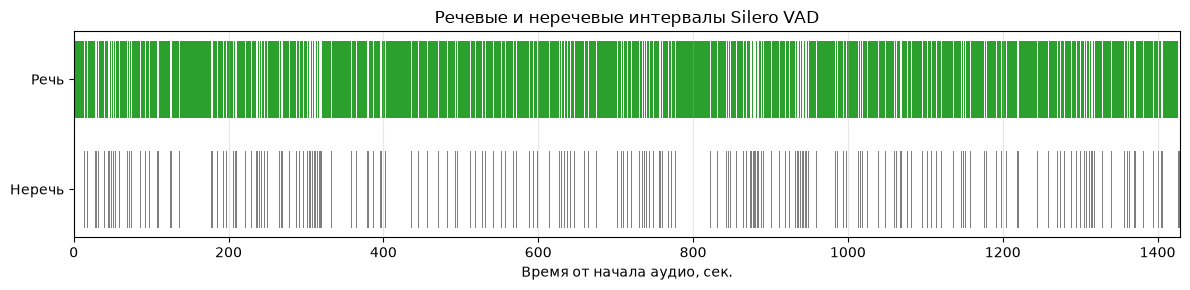

In [5]:
silero_speech_bars = list(zip(silero_speech_intervals["start"], silero_speech_durations))
silero_silence_bars = list(zip(silero_silence_intervals["start"], silero_pause_durations))

plt.figure(figsize=(12, 3))
plt.broken_barh(silero_speech_bars, (1, 0.7), facecolors="tab:green")
plt.broken_barh(silero_silence_bars, (0, 0.7), facecolors="tab:gray")
plt.xlim(0, silero_audio_duration)
plt.yticks([0.35, 1.35], ["Неречь", "Речь"])
plt.title("Речевые и неречевые интервалы Silero VAD")
plt.xlabel("Время от начала аудио, сек.")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 4.1. Ограничения Silero и смысл пауз

Этот эксперимент получает речевые интервалы нейросетевым детектором и неречевые интервалы как их дополнение. Таблицы `silero_speech_intervals` и `silero_silence_intervals` представлены в едином формате `start` / `end`; результаты и время работы появляются после запуска.

Количество и длительности пауз зависят от порогов, минимальных длительностей и расширения границ. При текущих настройках короткие участки речи отбрасываются, короткие провалы могут оставаться внутри речевого интервала, а границы не расширяются. Поэтому статистика описывает работу конкретной конфигурации детектора.

Неречевой интервал не гарантирует физическую тишину, а речевой — безошибочное обнаружение речи. Для выводов о качестве нужны прослушивание и эталонная разметка. Перед будущим сравнением и монтажом также нужно проверить временное смещение аудио относительно видео. На этом этапе сохраняем интервалы и описательную статистику без оценки F1 и удаления фрагментов.

<a id="whisper"></a>
## 5. Whisper — временные сегменты распознавания


В этом эксперименте Faster-Whisper распознаёт русскую речь в `test_video.mp4` и возвращает текст с временными границами сегментов. По промежуткам между ними получим предварительную оценку участков без распознанной речи.

Используем модель `small`, GPU (`cuda`) и точность `float16`. Время обработки измеряем без загрузки модели, но с декодированием аудио и полным распознаванием. Скорость относительно реального времени — длительность записи, делённая на время обработки.

Здесь «пауза» означает положительный промежуток **между соседними сегментами Whisper**. Начало до первого сегмента, конец после последнего и паузы внутри сегментов в эту статистику не входят. Такой промежуток может содержать шум, музыку или речь, которую модель не распознала.

Выберите ядро из `backend/venv/Scripts/python.exe` и выполняйте ячейки сверху вниз. [Документация Faster-Whisper](https://github.com/SYSTRAN/faster-whisper#usage).

Подключаем CUDA DLL для Windows, выбираем видео и настраиваем графики.

Сохраняем объекты, чтобы пути к CUDA DLL оставались подключены в ядре.

Ядро может стартовать из backend или из корня videoeditor.

In [1]:
import os
import sys
import time
from pathlib import Path

import nvidia.cublas
import nvidia.cudnn
import pandas as pd
import matplotlib.pyplot as plt


cublas_dll_directory = os.add_dll_directory(os.path.join(nvidia.cublas.__path__[0], "bin"))
cudnn_dll_directory = os.add_dll_directory(os.path.join(nvidia.cudnn.__path__[0], "bin"))

from faster_whisper import WhisperModel

%matplotlib inline


VIDEO_PATH = Path("test_video.mp4")
if not VIDEO_PATH.is_file():
    VIDEO_PATH = Path("backend") / "test_video.mp4"
VIDEO_PATH = VIDEO_PATH.resolve()
if not VIDEO_PATH.is_file():
    raise FileNotFoundError(f"Видео не найдено: {VIDEO_PATH}")

print("Python:", sys.executable)
print("Видео:", VIDEO_PATH)

Python: Z:\polikek 7\videoeditor\backend\venv\Scripts\python.exe
Видео: Z:\polikek 7\videoeditor\backend\test_video.mp4


Z:\polikek 7\videoeditor\backend\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Создаём Whisper small с CUDA/float16; загрузка не входит во время транскрипции.

In [2]:
model_size = "small"
device = "cuda"
compute_type = "float16"

print("Загрузка модели...")
model = WhisperModel(model_size, device=device, compute_type=compute_type)
print("Модель загружена.")

Загрузка модели...


Модель загружена.


Распознаём русскую речь видео и полностью потребляем генератор сегментов.

Распознавание завершается при обходе генератора, поэтому учитываем list() во времени.

In [3]:
print("Начинаем распознавание...")
started_at = time.perf_counter()

segments, info = model.transcribe(str(VIDEO_PATH), language="ru", vad_filter=False)

segments = list(segments)

elapsed = time.perf_counter() - started_at
print("Распознавание завершено.")

Начинаем распознавание...


Распознавание завершено.


Выводим длительность, время, x realtime и число сегментов.

In [4]:
realtime = info.duration / elapsed

print(f"Длительность видео: {info.duration:.1f} сек.")
print(f"Время обработки: {elapsed:.1f} сек.")
print(f"Скорость: {realtime:.2f}x realtime")
print(f"Количество сегментов: {len(segments)}")

Длительность видео: 1429.0 сек.
Время обработки: 108.2 сек.
Скорость: 13.21x realtime
Количество сегментов: 165


Преобразуем ASR-сегменты в таблицу start/end/duration/text.

In [5]:
speech_df = pd.DataFrame(
    [
        {
            "start": segment.start,
            "end": segment.end,
            "duration": segment.end - segment.start,
            "text": segment.text.strip(),
        }
        for segment in segments
    ],
    columns=["start", "end", "duration", "text"],
)

speech_df.head()

,start,end,duration,text
0,0.00,7.80,7.80,"Как бросить парнографию, просмотр грязных виде..."
1,7.80,17.76,9.96,"Других способов нету, поверьте. Будете ходить ..."
2,17.76,27.60,9.84,"Понимаете, это же отравляет душу, отчерстляет ..."
3,28.20,38.40,10.20,"Ау забилда. Понимаете, это единственный способ..."
4,38.40,48.80,10.40,Но самый мощный способ. Без этого вы будете хо...


Вычисляем промежуток до следующего сегмента, обрезая отрицательные значения до нуля.

shift(-1) берёт начало следующего сегмента; для последнего получается NaN.

In [6]:
next_start = speech_df["start"].shift(-1)
speech_df["pause_after"] = (next_start - speech_df["end"]).clip(lower=0)

speech_df.head()

,start,end,duration,text,pause_after
0,0.00,7.80,7.80,"Как бросить парнографию, просмотр грязных виде...",0.000000e+00
1,7.80,17.76,9.96,"Других способов нету, поверьте. Будете ходить ...",0.000000e+00
2,17.76,27.60,9.84,"Понимаете, это же отравляет душу, отчерстляет ...",6.000000e-01
3,28.20,38.40,10.20,"Ау забилда. Понимаете, это единственный способ...",0.000000e+00
4,38.40,48.80,10.40,Но самый мощный способ. Без этого вы будете хо...,7.105427e-15


Отбираем межсегментные паузы; это ещё не дополнение речи на всём видео.

In [7]:
pause_mask = speech_df["pause_after"] > 0
pauses_df = pd.DataFrame(
    {
        "pause_start": speech_df.loc[pause_mask, "end"],
        "pause_end": next_start.loc[pause_mask],
        "duration": speech_df.loc[pause_mask, "pause_after"],
    }
).reset_index(drop=True)

pauses_df.head()

,pause_start,pause_end,duration
0,27.6,28.2,6.000000e-01
1,48.8,48.8,7.105427e-15
2,148.0,149.0,1.000000e+00
3,208.0,210.0,2.000000e+00
4,268.0,269.0,1.000000e+00


Показываем статистику межсегментных пауз.

In [8]:
pause_durations = pauses_df["duration"]

print(f"Количество найденных пауз: {len(pauses_df)}")
if pauses_df.empty:
    print("Средняя, медианная и максимальная длительности: нет данных")
else:
    print(f"Средняя длительность: {pause_durations.mean():.3f} сек.")
    print(f"Медианная длительность: {pause_durations.median():.3f} сек.")
    print(f"Максимальная длительность: {pause_durations.max():.3f} сек.")

for threshold in [0.5, 1.0, 1.5, 2.0, 3.0]:
    count = (pause_durations >= threshold).sum()
    print(f"Пауз >= {threshold:.1f} сек.: {count}")

print(f"Суммарная длительность промежутков: {pause_durations.sum():.3f} сек.")

Количество найденных пауз: 19
Средняя длительность: 3.623 сек.
Медианная длительность: 1.000 сек.
Максимальная длительность: 25.000 сек.
Пауз >= 0.5 сек.: 17
Пауз >= 1.0 сек.: 15
Пауз >= 1.5 сек.: 6
Пауз >= 2.0 сек.: 6
Пауз >= 3.0 сек.: 5
Суммарная длительность промежутков: 68.840 сек.


Строим распределение длительности пауз.

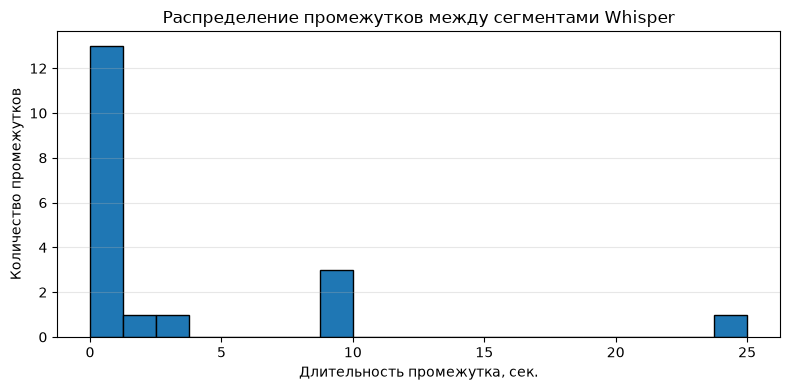

In [9]:
if pauses_df.empty:
    print("Положительных промежутков нет: гистограмму строить не из чего.")
else:
    plt.figure(figsize=(8, 4))
    plt.hist(pause_durations, bins=20, edgecolor="black")
    plt.title("Распределение промежутков между сегментами Whisper")
    plt.xlabel("Длительность промежутка, сек.")
    plt.ylabel("Количество промежутков")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

### 5.1. Ограничения ASR-сегментов для обнаружения неречи

Эксперимент позволяет получить первичную оценку промежутков без распознанной речи по временным сегментам Whisper. Численные результаты появляются в ячейках после реального запуска и зависят от видео и параметров модели.

Отсутствие распознанной речи **не гарантирует тишину или отсутствие речи**: модель может пропустить слова, а внутри промежутка могут оставаться другие звуки. Паузы внутри одного сегмента здесь также не обнаруживаются. Перед автоматическим удалением такие границы нужно проверять.

В дальнейшем эти результаты следует сравнить с методами анализа аудиосигнала и Voice Activity Detection (VAD).

<a id="spectral"></a>
## 6. Собственный метод Spectral VAD

Разделы 6–8 запускаются **последовательно, начиная с этого раздела**, в существующем `backend/venv`. Предыдущие эксперименты и их результаты не запускаются и не перезаписываются. Используются исходные WAV и `y_label` из MAT в `backend/.cache/kaist_vad/record_data/`.

**Протокол до оценки:** параметры Spectral VAD подбираются по всей `construction_site.wav`; три полные записи `room`, `park`, `bus_stop` остаются тестовыми. Это разделение по записям и условиям, но не по дикторам: в KAIST одни и те же два диктора. Для четырёх методов отдельно используется строго один и тот же 60-секундный вход `room.wav[280:340]`, без контекста за его границами. Этот участок не участвует в подборе параметров. Полные тестовые записи здесь оцениваются только для Spectral VAD, а не для всех четырёх методов.

Whisper сохраняет `small / cuda / float16`, исходные параметры `transcribe` и `vad_filter=False`. Единственное согласованное изменение — `language="ko"`, поскольку KAIST содержит корейскую речь. RMS сохраняет окна 30 мс, порог −40 dBFS и отсутствие сглаживания; Silero — исходную ONNX-конфигурацию. Предсказания из `test_video.mp4` не используются. Новые результаты сохраняются отдельно в `results/kaist_spectral_vad/`.

Это первый вычислительный этап KAIST. Позднее выполнены полные запуски всех четырёх методов; их единое сравнение находится в разделе 10.

Готовим окружение KAIST, фиксируем seed, разделение записей, параметры STFT и исходную сетку подбора.

In [1]:
import copy
import hashlib
import importlib.metadata
import inspect
import itertools
import json
import math
import os
import platform
import random
import subprocess
import sys
import time
import warnings
from dataclasses import asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat, wavfile
from scipy.signal import stft
from IPython.display import Markdown, display

sv_seed = 42
random.seed(sv_seed)
np.random.seed(sv_seed)
sv_backend = next(folder.resolve() for folder in (Path.cwd(), Path.cwd() / "backend") if (folder / "test_venv.ipynb").is_file())
sv_data_dir = sv_backend / ".cache" / "kaist_vad" / "record_data"
sv_results_dir = sv_backend / "results" / "kaist_spectral_vad"
sv_results_dir.mkdir(parents=True, exist_ok=True)
sv_previous = json.loads((sv_backend / "results" / "experiment_metadata.json").read_text(encoding="utf-8"))
sv_train_recording = "construction_site"
sv_test_recordings = ["room", "park", "bus_stop"]
sv_clip_recording, sv_clip_start, sv_clip_end = "room", 280.0, 340.0
sv_fs, sv_window_samples, sv_hop_samples = 16000, 400, 160
sv_feature_parameters = {
    "sample_rate_hz": sv_fs, "window_ms": 25, "hop_ms": 10,
    "window": "hann", "n_fft": 512, "band_hz": [200, 4000],
    "noise_quantile": 0.20, "energy_floor_dbfs": -60.0,
    "stft_scaling": "psd", "boundary": "zeros", "padded": True,
}
sv_grid = {
    "energy_margin_db": [0, 3, 6, 9, 12],
    "max_entropy": [0.65, 0.75, 0.85, 0.95],
    "max_flatness": [0.10, 0.25, 0.45, 0.65],
    "min_speech_ms": [100, 250], "max_gap_ms": [100, 250],
}
print("Python:", sys.executable)
print("Подбор:", sv_train_recording, "; тест:", sv_test_recordings)
print("Комбинаций параметров:", math.prod(map(len, sv_grid.values())))

Python: Z:\polikek 7\videoeditor\backend\venv\Scripts\python.exe
Подбор: construction_site ; тест: ['room', 'park', 'bus_stop']
Комбинаций параметров: 320


### 6.1. Загрузка, интервалы и функции оценки

Целевой класс — **речь**. Оценка проводится по всем аудиосэмплам 16 кГц, без допуска на границах и без исключения сложных участков. `Precision=TP/(TP+FP)`, `Recall=TP/(TP+FN)`, `F1=2TP/(2TP+FP+FN)`, `IoU=TP/(TP+FP+FN)`. При нулевом знаменателе используется 0. Время в матрице ошибок получается делением числа сэмплов на 16000. Это метрики занятости времени, а не точности распознавания текста или совпадения целых сегментов.

Целочисленный PCM переводится в float32 делением на полный диапазон типа, как при декодировании исходных экспериментов; нормализация по пику не применяется. Ground Truth не ресэмплируется: длина и частота WAV проверяются. Метки `1` объединяются в полуоткрытые интервалы `[start, end)`. В CSV для клипа время начинается с 0; `source_offset_s=280` явно хранится рядом с результатом.

Определяем загрузку WAV/MAT и служебные функции. Их определение не запускает модели и не записывает результаты.

In [2]:
def sv_load_recording(name, start=0.0, end=None):
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="Chunk .*not understood.*", category=wavfile.WavFileWarning)
        rate, raw = wavfile.read(sv_data_dir / f"{name}.wav", mmap=True)
    truth = loadmat(sv_data_dir / f"{name}.mat", variable_names=["y_label"])["y_label"].ravel()
    if rate != sv_fs or raw.ndim != 1 or len(raw) != len(truth) or not np.isin(truth, [0, 1]).all():
        raise ValueError(f"Некорректные WAV/MAT: {name}")
    first = int(round(start * rate))
    last = len(raw) if end is None else int(round(end * rate))
    if not 0 <= first < last <= len(raw):
        raise ValueError("Участок выходит за границы аудио")
    scale = max(abs(int(np.iinfo(raw.dtype).min)), int(np.iinfo(raw.dtype).max)) if np.issubdtype(raw.dtype, np.integer) else 1.0
    return np.asarray(raw[first:last], dtype=np.float32) / scale, truth[first:last].astype(bool)


def sv_runs(mask):
    changes = np.diff(np.pad(np.asarray(mask, dtype=np.int8), (1, 1)))
    return np.flatnonzero(changes == 1), np.flatnonzero(changes == -1)


def sv_mask_intervals(mask, step_samples, total_samples):
    starts, ends = sv_runs(mask)
    return pd.DataFrame({"start": starts * step_samples / sv_fs, "end": np.minimum(ends * step_samples, total_samples) / sv_fs})


def sv_merge_intervals(intervals, duration):
    merged = []
    for a, b in intervals[["start", "end"]].sort_values("start").itertuples(index=False, name=None):
        a, b = max(0.0, float(a)), min(duration, float(b))
        if b <= a:
            continue
        if merged and a <= merged[-1][1] + 1e-9:
            merged[-1][1] = max(merged[-1][1], b)
        else:
            merged.append([a, b])
    return pd.DataFrame(merged, columns=["start", "end"])


def sv_intervals_mask(intervals, total_samples):
    prediction = np.zeros(total_samples, dtype=bool)
    for a, b in intervals[["start", "end"]].itertuples(index=False, name=None):
        first = max(0, int(np.ceil(a * sv_fs - 1e-7)))
        last = min(total_samples, int(np.ceil(b * sv_fs - 1e-7)))
        prediction[first:last] = True
    return prediction


def sv_confusion_metrics(tp, fp, fn, tn):
    ratio = lambda a, b: float(a / b) if b else 0.0
    return {
        "precision": ratio(tp, tp + fp), "recall": ratio(tp, tp + fn),
        "f1": ratio(2 * tp, 2 * tp + fp + fn), "iou": ratio(tp, tp + fp + fn),
        "tp_samples": int(tp), "fp_samples": int(fp), "fn_samples": int(fn), "tn_samples": int(tn),
        "tp_s": tp / sv_fs, "fp_s": fp / sv_fs, "fn_s": fn / sv_fs, "tn_s": tn / sv_fs,
    }


def sv_metrics(truth, intervals):
    predicted = sv_intervals_mask(intervals, len(truth))
    tp = int(np.count_nonzero(truth & predicted))
    fp = int(np.count_nonzero(predicted)) - tp
    fn = int(np.count_nonzero(truth)) - tp
    return sv_confusion_metrics(tp, fp, fn, len(truth) - tp - fp - fn)


def sv_save_intervals(prefix, intervals, total_samples):
    prediction = sv_intervals_mask(intervals, total_samples)
    intervals.to_csv(sv_results_dir / f"{prefix}_speech_intervals.csv", index=False)
    sv_mask_intervals(~prediction, 1, total_samples).to_csv(sv_results_dir / f"{prefix}_silence_intervals.csv", index=False)

### 6.2. Спектральные признаки и пороговое решение

STFT: 16 кГц, периодическое окно Hann 400 сэмплов (25 мс), шаг 160 (10 мс), FFT 512. Используется [реализация SciPy STFT](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.stft.html). В полосе 200–4000 Гц рассчитываются:

- **Энергия**: интеграл односторонней спектральной плотности мощности, затем `10 log10(E)` в dBFS относительно единичной мощности.
- **Нормированная энтропия**: `−Σ p log(p) / log(K)`, где `p` — нормированные мощности K частотных бинов.
- **Спектральная плоскостность**: геометрическое среднее мощностей, делённое на арифметическое. Белый шум обычно имеет более высокие энтропию и плоскостность, чем выраженный гармонический спектр; тональный шум тоже может пройти такое правило.

Речь требует одновременного выполнения трёх порогов. Энергетический порог равен максимуму из −60 dBFS и 20-го процентиля энергии текущего входа плюс настраиваемый запас. Это ненейросетевой адаптивный baseline: оценка шума использует только аудио, но весь обрабатываемый вход, поэтому метод офлайн. Для клипа процентиль считается только по клипу, а не по остальной комнате.

После решения заполняются **внутренние** паузы не длиннее `max_gap_ms`, затем удаляются речевые участки короче `min_speech_ms`; начала и концы записи не дополняются. Решение кадра относится к `[j·10 мс, (j+1)·10 мс)`, последний слот обрезается по длине аудио. STFT центрирован, поэтому использует до 12,5 мс будущего контекста; в начале и конце есть нулевое дополнение. Ground Truth не сдвигается и не сглаживается.

Реализуем STFT-признаки, энергетический порог и сглаживание. Исходные алгоритм и константы сохранены.

In [3]:
def sv_spectral_features(audio):
    frequencies, times, spectrum = stft(
        audio, fs=sv_fs, window=sv_feature_parameters["window"],
        nperseg=sv_window_samples, noverlap=sv_window_samples - sv_hop_samples,
        nfft=sv_feature_parameters["n_fft"], boundary="zeros", padded=True, scaling="psd",
    )
    frame_count = (len(audio) + sv_hop_samples - 1) // sv_hop_samples
    low, high = sv_feature_parameters["band_hz"]
    band = (frequencies >= low) & (frequencies <= high)
    power = np.maximum(np.abs(spectrum[band, :frame_count]) ** 2, 1e-20)
    probabilities = power / power.sum(axis=0)
    energy = 2 * power.sum(axis=0) * sv_fs / sv_feature_parameters["n_fft"]
    return pd.DataFrame({
        "start": np.arange(frame_count) * sv_hop_samples / sv_fs,
        "end": np.minimum((np.arange(frame_count) + 1) * sv_hop_samples, len(audio)) / sv_fs,
        "energy_dbfs": 10 * np.log10(np.maximum(energy, 1e-20)),
        "entropy": -np.sum(probabilities * np.log(probabilities), axis=0) / np.log(power.shape[0]),
        "flatness": np.exp(np.mean(np.log(power), axis=0)) / np.mean(power, axis=0),
    })


def sv_smooth_mask(mask, parameters):
    mask = np.array(mask, dtype=bool, copy=True)
    gap_limit = round(parameters["max_gap_ms"] / 10)
    starts, ends = sv_runs(~mask)
    for a, b in zip(starts, ends):
        if a > 0 and b < len(mask) and b - a <= gap_limit:
            mask[a:b] = True
    minimum = int(np.ceil(parameters["min_speech_ms"] / 10))
    starts, ends = sv_runs(mask)
    for a, b in zip(starts, ends):
        if b - a < minimum:
            mask[a:b] = False
    return mask


def sv_spectral_decision(features, parameters):
    threshold = max(sv_feature_parameters["energy_floor_dbfs"], float(features["energy_dbfs"].quantile(sv_feature_parameters["noise_quantile"])) + parameters["energy_margin_db"])
    raw = (
        (features["energy_dbfs"].to_numpy() >= threshold)
        & (features["entropy"].to_numpy() <= parameters["max_entropy"])
        & (features["flatness"].to_numpy() <= parameters["max_flatness"])
    )
    return sv_smooth_mask(raw, parameters), threshold

<a id="tuning"></a>
## 7. Подбор параметров только на construction_site

Сетка задана до просмотра тестовых метрик: 320 комбинаций порогов и длительностей. Выбирается максимальный F1 на полной настроечной записи; при равенстве используются IoU, затем Precision, затем исходный порядок сетки. Для ускорения перебора внутри 10-мс слотов сохраняется точное число речевых и неречевых **сэмплов**, поэтому граничные слоты не округляют Ground Truth до большинства. Настроечный F1 не является тестовым результатом. После выбора параметры фиксируются и на тестовых записях больше не подбираются.

Выполняем исходный перебор 320 комбинаций на настроечной записи. Тестовые записи не участвуют.

In [4]:
sv_train_audio, sv_train_truth = sv_load_recording(sv_train_recording)
sv_started = time.perf_counter()
sv_train_features = sv_spectral_features(sv_train_audio)
sv_train_feature_seconds = time.perf_counter() - sv_started
sv_offsets = np.arange(0, len(sv_train_truth), sv_hop_samples)
sv_truth_counts = np.add.reduceat(sv_train_truth, sv_offsets, dtype=np.int64)
sv_slot_sizes = np.minimum(sv_hop_samples, len(sv_train_truth) - sv_offsets)
sv_tuning_rows = []
sv_tuning_started = time.perf_counter()
for values in itertools.product(*sv_grid.values()):
    parameters = dict(zip(sv_grid, values))
    prediction, threshold = sv_spectral_decision(sv_train_features, parameters)
    tp = int(sv_truth_counts[prediction].sum())
    fp = int(sv_slot_sizes[prediction].sum()) - tp
    fn = int(sv_truth_counts.sum()) - tp
    metrics = sv_confusion_metrics(tp, fp, fn, len(sv_train_truth) - tp - fp - fn)
    sv_tuning_rows.append({**parameters, "energy_threshold_dbfs": threshold, **metrics})
sv_tuning_seconds = time.perf_counter() - sv_tuning_started
sv_tuning = pd.DataFrame(sv_tuning_rows).sort_values(["f1", "iou", "precision"], ascending=False, kind="stable").reset_index(drop=True)
sv_selected = {key: int(sv_tuning.loc[0, key]) if key in {"min_speech_ms", "max_gap_ms"} else float(sv_tuning.loc[0, key]) for key in sv_grid}
sv_frozen_parameters = copy.deepcopy(sv_selected)
sv_tuning.to_csv(sv_results_dir / "spectral_tuning.csv", index=False)
(sv_results_dir / "selected_spectral_parameters.json").write_text(json.dumps({"feature_parameters": sv_feature_parameters, "decision_parameters": sv_selected, "tuning_recording": sv_train_recording}, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print("Зафиксированные параметры:", sv_selected)
print(f"STFT настроечной записи: {sv_train_feature_seconds:.3f} с; перебор: {sv_tuning_seconds:.3f} с")
display(sv_tuning.head(10))

Зафиксированные параметры: {'energy_margin_db': 12.0, 'max_entropy': 0.75, 'max_flatness': 0.1, 'min_speech_ms': 250, 'max_gap_ms': 250}
STFT настроечной записи: 1.367 с; перебор: 2.072 с


,energy_margin_db,max_entropy,max_flatness,min_speech_ms,max_gap_ms,energy_threshold_dbfs,precision,recall,f1,iou,tp_samples,fp_samples,fn_samples,tn_samples,tp_s,fp_s,fn_s,tn_s
0,12,0.75,0.10,250,250,-31.82185,0.923847,0.886808,0.904949,0.826398,6827157,562763,871420,20565212,426.697313,35.172688,54.463750,1285.325750
1,12,0.85,0.10,250,250,-31.82185,0.923228,0.886808,0.904651,0.825902,6827157,567723,871420,20560252,426.697313,35.482687,54.463750,1285.015750
2,12,0.95,0.10,250,250,-31.82185,0.923228,0.886808,0.904651,0.825902,6827157,567723,871420,20560252,426.697313,35.482687,54.463750,1285.015750
3,12,0.65,0.25,250,250,-31.82185,0.921768,0.887398,0.904256,0.825244,6831700,579820,866877,20548155,426.981250,36.238750,54.179812,1284.259687
4,12,0.65,0.45,250,250,-31.82185,0.921768,0.887398,0.904256,0.825244,6831700,579820,866877,20548155,426.981250,36.238750,54.179812,1284.259687
5,12,0.65,0.65,250,250,-31.82185,0.921768,0.887398,0.904256,0.825244,6831700,579820,866877,20548155,426.981250,36.238750,54.179812,1284.259687
6,12,0.65,0.10,250,250,-31.82185,0.930365,0.877170,0.902985,0.823129,6752963,505437,945614,20622538,422.060187,31.589813,59.100875,1288.908625
7,12,0.75,0.25,250,250,-31.82185,0.901565,0.901019,0.901292,0.820320,6936567,757353,762010,20370622,433.535438,47.334562,47.625625,1273.163875
8,9,0.65,0.10,250,250,-34.82185,0.884089,0.918704,0.901064,0.819942,7072710,927290,625867,20200685,442.044375,57.955625,39.116687,1262.542813
9,12,0.75,0.10,100,250,-31.82185,0.911256,0.889967,0.900485,0.818985,6851477,667243,847100,20460732,428.217312,41.702688,52.943750,1278.795750


<a id="evaluation"></a>
## 8. Оценка по Ground Truth

Время обработки включает извлечение признаков, адаптивный энергетический порог, сглаживание и формирование интервалов. Загрузка WAV/MAT, расчёт метрик и сохранение файлов исключены. Даже для настроечной записи после выбора проводится отдельный проход с зафиксированными параметрами; перебор в это время не включается. `x realtime = длительность / время обработки`. Это один измеренный запуск, не усреднённый benchmark.

Оцениваем Spectral VAD с зафиксированными параметрами на полных записях первого этапа.

In [5]:
sv_full_rows = []
for name in [sv_train_recording, *sv_test_recordings]:
    audio, truth = sv_load_recording(name)
    started = time.perf_counter()
    features = sv_spectral_features(audio)
    mask, threshold = sv_spectral_decision(features, sv_selected)
    intervals = sv_mask_intervals(mask, sv_hop_samples, len(audio))
    elapsed = time.perf_counter() - started
    row = {"recording": name, "split": "tuning" if name == sv_train_recording else "test", "duration_s": len(audio) / sv_fs, "energy_threshold_dbfs": threshold, "processing_s": elapsed, "x_realtime": len(audio) / sv_fs / elapsed, "speech_intervals": len(intervals), **sv_metrics(truth, intervals)}
    sv_full_rows.append(row)
    sv_save_intervals(f"{name}_spectral", intervals, len(audio))
    sv_save_intervals(f"{name}_ground_truth", sv_mask_intervals(truth, 1, len(audio)), len(audio))
    print(name, row["split"], f'F1={row["f1"]:.4f}, IoU={row["iou"]:.4f}, {elapsed:.3f} с', flush=True)
sv_full_metrics = pd.DataFrame(sv_full_rows)
sv_full_metrics.to_csv(sv_results_dir / "spectral_recording_metrics.csv", index=False)
sv_tests = sv_full_metrics[sv_full_metrics["split"] == "test"]
sv_micro = sv_confusion_metrics(*(int(sv_tests[column].sum()) for column in ["tp_samples", "fp_samples", "fn_samples", "tn_samples"]))
sv_test_aggregate = pd.DataFrame([
    {"aggregation": "macro_three_test_recordings", **{key: float(sv_tests[key].mean()) for key in ["precision", "recall", "f1", "iou"]}},
    {"aggregation": "micro_three_test_recordings", **sv_micro},
])
sv_test_aggregate.to_csv(sv_results_dir / "spectral_test_aggregate.csv", index=False)
assert sv_selected == sv_frozen_parameters
display(sv_full_metrics[["recording", "split", "precision", "recall", "f1", "iou", "processing_s", "x_realtime"]].round(4))
display(sv_test_aggregate[["aggregation", "precision", "recall", "f1", "iou"]].round(4))
del audio, truth, features, mask, sv_train_audio, sv_train_truth, sv_train_features

construction_site tuning F1=0.9049, IoU=0.8264, 1.268 с


room test F1=0.9320, IoU=0.8727, 1.041 с


park test F1=0.8842, IoU=0.7924, 0.968 с


bus_stop test F1=0.7017, IoU=0.5405, 0.958 с


,recording,split,precision,recall,f1,iou,processing_s,x_realtime
0,construction_site,tuning,0.9238,0.8868,0.9049,0.8264,1.2684,1420.3829
1,room,test,0.9108,0.9543,0.9320,0.8727,1.0411,1731.3152
2,park,test,0.8957,0.8729,0.8842,0.7924,0.9677,1864.3214
3,bus_stop,test,0.9796,0.5466,0.7017,0.5405,0.9584,1879.7408


,aggregation,precision,recall,f1,iou
0,macro_three_test_recordings,0.9287,0.7913,0.8393,0.7352
1,micro_three_test_recordings,0.9250,0.7640,0.8368,0.7195


### 8.1. Отдельный эксперимент: room.wav, 280–340 с

Все методы получают один и тот же новый mono float32-массив длиной 60 секунд. RMS повторяет вычисление RMS в неперекрывающихся 30-мс окнах и объединение соседних выбранных окон из предыдущего раздела. Silero вызывает тот же `get_speech_timestamps` с теми же `VadOptions`; Whisper выполняет новую транскрипцию с полным потреблением генератора. Соседние и перекрывающиеся ASR-сегменты объединяются в речевые интервалы без дополнительного расширения.

Время ниже начинается с уже декодированного массива и включает полный вызов метода и перевод в интервалы. Инициализация моделей измеряется отдельно. Поэтому эти времена нельзя напрямую сопоставлять со старыми замерами, включавшими декодирование видео. RMS, Spectral и Silero работают на CPU, Whisper — на GPU. Для каждого метода сохраняется статус; при ошибке метрики остаются пустыми, причина печатается и сохраняется в JSON — ошибка не подменяется предсказанием «везде тишина».

Подготавливаем единый клип и запускаем Spectral VAD и RMS с прежними настройками.

In [6]:
sv_clip_audio, sv_clip_truth = sv_load_recording(sv_clip_recording, sv_clip_start, sv_clip_end)
sv_clip_duration = len(sv_clip_audio) / sv_fs
sv_clip_prefix = "room_280_340"
sv_clip_gt = sv_mask_intervals(sv_clip_truth, 1, len(sv_clip_audio))
sv_save_intervals(f"{sv_clip_prefix}_ground_truth", sv_clip_gt, len(sv_clip_audio))
sv_clip_predictions = {}
sv_clip_rows = []
sv_model_initialization = {}
sv_errors = {}
sv_rms_parameters = copy.deepcopy(sv_previous["methods"]["rms"]["parameters"])
sv_whisper_parameters = copy.deepcopy(sv_previous["methods"]["whisper"]["parameters"])
sv_whisper_kwargs = copy.deepcopy(sv_whisper_parameters["transcribe_call_arguments"])
sv_whisper_kwargs.pop("audio")
sv_whisper_kwargs["language"] = "ko"
sv_silero_parameters = copy.deepcopy(sv_previous["methods"]["silero"]["parameters"])


def sv_rms_mask_to_intervals(windows, mask):
    intervals = []
    interval_start = None
    interval_end = None
    for start, end, selected in zip(windows["start"], windows["end"], mask):
        if selected:
            if interval_start is None:
                interval_start = start
            interval_end = end
        elif interval_start is not None:
            intervals.append({"start": interval_start, "end": interval_end})
            interval_start = None
    if interval_start is not None:
        intervals.append({"start": interval_start, "end": interval_end})
    return pd.DataFrame(intervals, columns=["start", "end"])


def sv_run_rms(audio):
    windows = []
    window_size = sv_rms_parameters["window_samples"]
    for first in range(0, len(audio), window_size):
        last = min(first + window_size, len(audio))
        value = np.sqrt(np.mean(audio[first:last] ** 2, dtype=np.float64))
        windows.append({"start": first / sv_fs, "end": last / sv_fs, "rms": value})
    windows = pd.DataFrame(windows)
    dbfs = 20 * np.log10(windows["rms"].clip(lower=sv_rms_parameters["log_rms_floor"]))
    return sv_rms_mask_to_intervals(windows, dbfs >= sv_rms_parameters["threshold_dbfs"])


def sv_run_spectral(audio):
    features = sv_spectral_features(audio)
    mask, threshold = sv_spectral_decision(features, sv_selected)
    return sv_mask_intervals(mask, sv_hop_samples, len(audio)), features, mask, threshold


def sv_add_clip_result(method, intervals, elapsed):
    metrics = sv_metrics(sv_clip_truth, intervals)
    sv_clip_predictions[method] = intervals
    sv_clip_rows.append({"method": method, "recording": sv_clip_recording, "source_offset_s": sv_clip_start, "duration_s": sv_clip_duration, "status": "ok", "processing_s": elapsed, "x_realtime": sv_clip_duration / elapsed, "speech_intervals": len(intervals), **metrics})
    sv_save_intervals(f"{sv_clip_prefix}_{method}", intervals, len(sv_clip_audio))
    print(method, f'F1={metrics["f1"]:.4f}, {elapsed:.4f} с', flush=True)


sv_started = time.perf_counter()
sv_intervals, sv_clip_features, sv_clip_spectral_mask, sv_clip_energy_threshold = sv_run_spectral(sv_clip_audio)
sv_add_clip_result("spectral", sv_intervals, time.perf_counter() - sv_started)
sv_clip_features["speech"] = sv_clip_spectral_mask.astype(int)
sv_clip_features.to_csv(sv_results_dir / "room_280_340_spectral_features.csv", index=False)
sv_started = time.perf_counter()
sv_intervals = sv_run_rms(sv_clip_audio)
sv_add_clip_result("rms", sv_intervals, time.perf_counter() - sv_started)

spectral F1=0.9607, 0.0323 с


rms F1=0.9000, 0.0163 с


Запускаем Silero на том же клипе; ошибка не подменяется искусственными предсказаниями.

In [7]:
try:
    from faster_whisper.vad import VadOptions, get_speech_timestamps, get_vad_model
    sv_options = VadOptions(
        threshold=sv_silero_parameters["threshold"], neg_threshold=sv_silero_parameters["neg_threshold"],
        min_speech_duration_ms=sv_silero_parameters["min_speech_duration_ms"],
        max_speech_duration_s=float("inf"), min_silence_duration_ms=sv_silero_parameters["min_silence_duration_ms"],
        speech_pad_ms=sv_silero_parameters["speech_pad_ms"],
    )
    sv_started = time.perf_counter()
    sv_silero_model = get_vad_model()
    sv_model_initialization["silero"] = time.perf_counter() - sv_started
    sv_started = time.perf_counter()
    sv_sample_intervals = get_speech_timestamps(sv_clip_audio, vad_options=sv_options, sampling_rate=sv_fs)
    sv_intervals = pd.DataFrame(sv_sample_intervals, columns=["start", "end"], dtype=float) / sv_fs
    sv_add_clip_result("silero", sv_intervals, time.perf_counter() - sv_started)
    print("Silero:", asdict(sv_options), sv_silero_model.session.get_providers())
except Exception as error:
    sv_errors["silero"] = f"{type(error).__name__}: {error}"
    print("Silero не выполнен:", sv_errors["silero"])

Z:\polikek 7\videoeditor\backend\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


silero F1=0.9549, 0.1217 с


Silero: {'threshold': 0.5, 'neg_threshold': 0.35, 'min_speech_duration_ms': 250, 'max_speech_duration_s': inf, 'min_silence_duration_ms': 250, 'speech_pad_ms': 0} ['CPUExecutionProvider']


Запускаем Whisper small на том же клипе с корейским языком и остальными прежними параметрами.

In [8]:
sv_cuda_dll_handles = []
try:
    if os.name == "nt":
        import nvidia.cublas
        import nvidia.cudnn
        for package in (nvidia.cublas, nvidia.cudnn):
            sv_cuda_dll_handles.append(os.add_dll_directory(str(Path(package.__path__[0]) / "bin")))
    import ctranslate2
    from faster_whisper import WhisperModel
    ctranslate2.set_random_seed(sv_seed)
    sv_started = time.perf_counter()
    sv_whisper_model = WhisperModel(sv_whisper_parameters["model_size"], device=sv_whisper_parameters["device"], compute_type=sv_whisper_parameters["compute_type"])
    sv_model_initialization["whisper"] = time.perf_counter() - sv_started
    sv_started = time.perf_counter()
    sv_segments, sv_info = sv_whisper_model.transcribe(sv_clip_audio, **sv_whisper_kwargs)
    sv_segments = list(sv_segments)
    sv_segment_table = pd.DataFrame([
        {"start": segment.start, "end": segment.end, "text": segment.text, "avg_logprob": segment.avg_logprob, "no_speech_prob": segment.no_speech_prob, "temperature": segment.temperature}
        for segment in sv_segments
    ], columns=["start", "end", "text", "avg_logprob", "no_speech_prob", "temperature"])
    sv_intervals = sv_merge_intervals(sv_segment_table, sv_clip_duration)
    sv_add_clip_result("whisper", sv_intervals, time.perf_counter() - sv_started)
    sv_segment_table.to_csv(sv_results_dir / "room_280_340_whisper_segments.csv", index=False)
    print("Whisper:", sv_whisper_parameters["model_size"], sv_whisper_parameters["device"], sv_whisper_parameters["compute_type"], "language=ko", "сегментов:", len(sv_segments))
except Exception as error:
    sv_errors["whisper"] = f"{type(error).__name__}: {error}"
    print("Whisper не выполнен:", sv_errors["whisper"])

whisper F1=0.8905, 6.2831 с


Whisper: small cuda float16 language=ko сегментов: 32


### 8.2. Фиксация параметров и происхождения результатов

Сохраняются таблицы подбора, метрик, признаки клипа, речевые и неречевые интервалы, ASR-сегменты, фактические параметры, версии, аппаратная среда и SHA-256 WAV/MAT. Старые CSV и `experiment_metadata.json` остаются нетронутыми. Следующие визуализации читают **новые CSV из этого каталога**, а не запускают модели. Для повторного просмотра достаточно ячейки импортов/путей и ячеек визуализации в конце раздела.

Сохраняем первый этап KAIST, включая параметры, версии, SHA-256 и статусы.

In [9]:
for method, message in sv_errors.items():
    sv_clip_rows.append({"method": method, "recording": sv_clip_recording, "source_offset_s": sv_clip_start, "duration_s": sv_clip_duration, "status": "failed", "error": message})
sv_clip_metrics = pd.DataFrame(sv_clip_rows)
sv_clip_metrics.to_csv(sv_results_dir / "room_280_340_metrics.csv", index=False)
sv_sources = []
for name in [sv_train_recording, *sv_test_recordings]:
    for suffix in [".wav", ".mat"]:
        source = sv_data_dir / f"{name}{suffix}"
        with source.open("rb") as stream:
            digest = hashlib.file_digest(stream, "sha256").hexdigest()
        sv_sources.append({"recording": name, "split": "tuning" if name == sv_train_recording else "test", "file": source.name, "size_bytes": source.stat().st_size, "sha256": digest})
pd.DataFrame(sv_sources).to_csv(sv_results_dir / "sources.csv", index=False)
sv_versions = {}
for package in ["numpy", "pandas", "scipy", "matplotlib", "faster-whisper", "ctranslate2", "onnxruntime", "av", "nvidia-cublas-cu12", "nvidia-cudnn-cu12"]:
    try:
        sv_versions[package] = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        sv_versions[package] = None
try:
    sv_gpu = subprocess.check_output(["nvidia-smi", "--query-gpu=name,driver_version,memory.total", "--format=csv,noheader"], text=True, timeout=10).strip()
except (OSError, subprocess.SubprocessError):
    sv_gpu = None
sv_manifest = {
    "schema_version": 1, "seed": sv_seed,
    "created_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "dataset": "KAIST VAD Recorded Dataset", "source_url": "https://github.com/jtkim-kaist/VAD#recorded-dataset",
    "sources": sv_sources, "interval_convention": "[start, end)", "time_unit": "seconds",
    "protocol": {"tuning_recording": sv_train_recording, "test_recordings": sv_test_recordings, "selection_metric": "maximum sample-level F1 on tuning recording", "test_parameters_retuned": False, "speaker_independent": False, "full_recordings_evaluated_methods": ["spectral"], "four_method_clip": {"recording": sv_clip_recording, "start": sv_clip_start, "end": sv_clip_end, "csv_time_origin": "clip start", "all_methods_input": "same 60-second float32 mono array, no outside context"}},
    "evaluation": {"positive_class": "speech", "resolution_hz": sv_fs, "boundary_collar_s": 0, "zero_division": 0, "ground_truth_smoothing": False, "timing": "already-decoded float32 audio to merged intervals, excluding model initialization, metrics and file IO; single run", "x_realtime": "audio_duration / processing_seconds"},
    "spectral": {"features": sv_feature_parameters, "grid": sv_grid, "selected_parameters": sv_selected, "smoothing_order": ["fill internal gaps <= max_gap_ms", "remove speech runs < min_speech_ms"], "frame_decision_scope": "[j*0.01, (j+1)*0.01), final slot clipped", "noise_estimation": "20th percentile of energy of the current input only; offline, no GT", "clip_energy_threshold_dbfs": sv_clip_energy_threshold, "tuning_features_seconds": sv_train_feature_seconds, "tuning_search_seconds": sv_tuning_seconds},
    "rms": sv_rms_parameters,
    "silero": sv_silero_parameters,
    "whisper": {"model_size": sv_whisper_parameters["model_size"], "device": sv_whisper_parameters["device"], "compute_type": sv_whisper_parameters["compute_type"], "transcribe_call_arguments": sv_whisper_kwargs, "change_from_previous_experiment": "language ru -> ko, authorized for Korean dataset"},
    "model_initialization_seconds": sv_model_initialization, "errors": sv_errors,
    "environment": {"python": platform.python_version(), "os": platform.platform(), "cpu": platform.processor(), "gpu": sv_gpu, "versions": sv_versions},
    "limitations": ["Only one recording used for tuning; no speaker-independent split", "Four-method metrics are from one 60-second held-out room excerpt", "Spectral thresholds may not transfer to changing noise conditions or tonal interference", "Whisper ASR timestamps are not a speech-specific VAD output", "CPU and GPU timing, single run, model initialization excluded; seed does not guarantee GPU determinism"],
}
sv_manifest["csv_files"] = {}
for csv_path in sorted(sv_results_dir.glob("*.csv")):
    table = pd.read_csv(csv_path, float_precision="round_trip")
    sv_manifest["csv_files"][csv_path.name] = {"rows": len(table), "columns": table.columns.tolist(), "sha256": hashlib.sha256(csv_path.read_bytes()).hexdigest()}
(sv_results_dir / "experiment.json").write_text(json.dumps(sv_manifest, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
assert sv_selected == sv_frozen_parameters
print("Результаты сохранены:", sv_results_dir)
print("Ошибки выполнения:", sv_errors or "нет")

Результаты сохранены: Z:\polikek 7\videoeditor\backend\results\kaist_spectral_vad
Ошибки выполнения: нет


<a id="comparisons"></a>
## 9. Первичные сравнения и сохранённые наблюдения

Здесь сохранены исходные диагностические сравнения. Первые 120 секунд относятся к test_video.mp4, а отдельный 60-секундный пример — к KAIST. Они не заменяют итоговую оценку трёх полных WAV в разделе 10. Повторные импорты в самостоятельных блоках оставлены для их независимого воспроизведения.

### 9.1. Исходное видео: первые 120 секунд

Сопоставим результаты Whisper, RMS при **−40 dBFS** и Silero VAD на одном временном участке. Используем зафиксированные CSV и JSON из `backend/results/`. После перезапуска ядра выполняйте только сравнительные ячейки этого раздела: первая Code-ячейка загружает результаты с диска. Запуск предыдущих вычислительных разделов для сравнения не требуется.

Для Whisper считаем речью полную длительность распознанных сегментов, для RMS — окна не ниже −40 dBFS, для Silero — интервалы VAD с ранее заданными параметрами. Эти определения различаются: пауза внутри сегмента Whisper здесь входит в его речевой интервал.

Обрезаем интервалы по границам участка и объединяем пересечения и соприкосновения, чтобы исключить двойной подсчёт. Неречь для каждого метода — дополнение до полной длительности участка, включая его начало и конец. На графике цветные полосы показывают решение «речь», серый фон — «неречь». Это сравнение решений методов без эталонной разметки и оценки качества.

Загружаем CSV/JSON исходного видео и приводим интервалы к общей области.

Допуск устраняет только погрешность чисел, а не реальные короткие паузы.

Обрезает интервалы и объединяет пересекающиеся или соприкасающиеся.

In [22]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

results_dir = Path("results")
if not (results_dir / "experiment_metadata.json").is_file():
    results_dir = Path("backend") / "results"
results_dir = results_dir.resolve()
saved_results = json.loads((results_dir / "experiment_metadata.json").read_text(encoding="utf-8"))
result_tables = {
    filename: pd.read_csv(
        results_dir / filename,
        encoding="utf-8",
        float_precision="round_trip",
        keep_default_na=False,
        na_values={"pause_after": [""]},
    )
    for filename in saved_results["csv_files"]
}

comparison_start = 0.0
comparison_end = min(120.0, saved_results["source"]["audio_duration_seconds"])
comparison_duration = comparison_end - comparison_start
assert saved_results["methods"]["rms"]["parameters"]["threshold_dbfs"] == -40


def comparison_clip_and_merge(intervals_df, start, end):

    clipped = intervals_df[["start", "end"]].copy()
    clipped["start"] = clipped["start"].clip(lower=start)
    clipped["end"] = clipped["end"].clip(upper=end)
    clipped = clipped[clipped["end"] > clipped["start"]].sort_values("start")
    merged = []

    for interval_start, interval_end in clipped.itertuples(index=False, name=None):
        
        if merged and interval_start <= merged[-1]["end"] + 1e-9:
            merged[-1]["end"] = max(merged[-1]["end"], interval_end)
        else:
            merged.append({"start": interval_start, "end": interval_end})

    return pd.DataFrame(merged, columns=["start", "end"])

comparison_source_intervals = {
    "Whisper": result_tables["whisper_speech_intervals.csv"],
    "RMS": result_tables["rms_speech_intervals.csv"],
    "Silero VAD": result_tables["silero_speech_intervals.csv"],
}
comparison_speech_intervals = {
    method: comparison_clip_and_merge(intervals, comparison_start, comparison_end)
    for method, intervals in comparison_source_intervals.items()
}
print(f"Участок сравнения: {comparison_start:.1f}–{comparison_end:.1f} сек.; RMS: −40 dBFS")

Участок сравнения: 0.0–120.0 сек.; RMS: −40 dBFS


### 9.2. Проверка зафиксированных результатов исходного видео

Полные таблицы находятся в `backend/results/`: `whisper_segments.csv` и по две таблицы `speech_intervals` / `silence_intervals` для Whisper, RMS и Silero. Временные границы хранятся в секундах как `start` / `end`, без округления при экспорте. В Whisper-сегментах также сохранены `duration`, `text` и `pause_after`.

`experiment_metadata.json` содержит параметры, версии библиотек, длительность и контрольную сумму исходного видео, времена обработки, статистику, сравнение первых 120 секунд и контрольные суммы CSV. Неречевые интервалы в CSV покрывают дополнение речи на всей аудиодорожке, включая начало и конец; прежняя статистика Whisper между сегментами записана отдельно.

До экспорта полные таблицы не сохранялись. Поэтому CSV фиксируют один новый запуск с прежними параметрами; старый вывод notebook оставлен как исторический результат и указан в JSON отдельно. Для дальнейших сравнений используйте `result_tables` и `saved_results`, которые сравнительная ячейка загружает из файлов. Следующая ячейка проверяет эти файлы без запуска моделей.

Проверяем SHA-256, число строк и столбцы без повторного распознавания.

In [4]:
import hashlib

saved_file_rows = []
for filename, description in saved_results["csv_files"].items():
    table = result_tables[filename]
    digest = hashlib.sha256((results_dir / filename).read_bytes()).hexdigest()
    assert digest == description["sha256"], f"Изменён файл: {filename}"
    assert len(table) == description["rows"]
    assert table.columns.tolist() == description["columns"]
    saved_file_rows.append({"file": filename, "rows": len(table), "sha256_ok": True})

print("CSV загружены; число строк, столбцы и контрольные суммы совпадают с JSON.")
pd.DataFrame(saved_file_rows)

CSV загружены; число строк, столбцы и контрольные суммы совпадают с JSON.


,file,rows,sha256_ok
0,whisper_segments.csv,328,True
1,whisper_speech_intervals.csv,34,True
2,whisper_silence_intervals.csv,34,True
3,rms_speech_intervals.csv,2634,True
4,rms_silence_intervals.csv,2635,True
5,silero_speech_intervals.csv,337,True
6,silero_silence_intervals.csv,338,True


Подсчитываем время и доли речи/неречи первых 120 секунд.

In [23]:
comparison_rows = []
for method, intervals in comparison_speech_intervals.items():
    speech_seconds = (intervals["end"] - intervals["start"]).sum()
    non_speech_seconds = comparison_duration - speech_seconds
    comparison_rows.append(
        {
            "method": method,
            "speech_intervals": len(intervals),
            "speech_s": speech_seconds,
            "non_speech_s": non_speech_seconds,
            "speech_percent": 100 * speech_seconds / comparison_duration,
            "non_speech_percent": 100 * non_speech_seconds / comparison_duration,
        }
    )

comparison_summary_df = pd.DataFrame(comparison_rows)
comparison_summary_df.round(3)

,method,speech_intervals,speech_s,non_speech_s,speech_percent,non_speech_percent
0,Whisper,2,119.400,0.600,99.500,0.500
1,RMS,186,111.630,8.370,93.025,6.975
2,Silero VAD,36,89.632,30.368,74.693,25.307


Показываем синхронные дорожки решений на исходном видео.

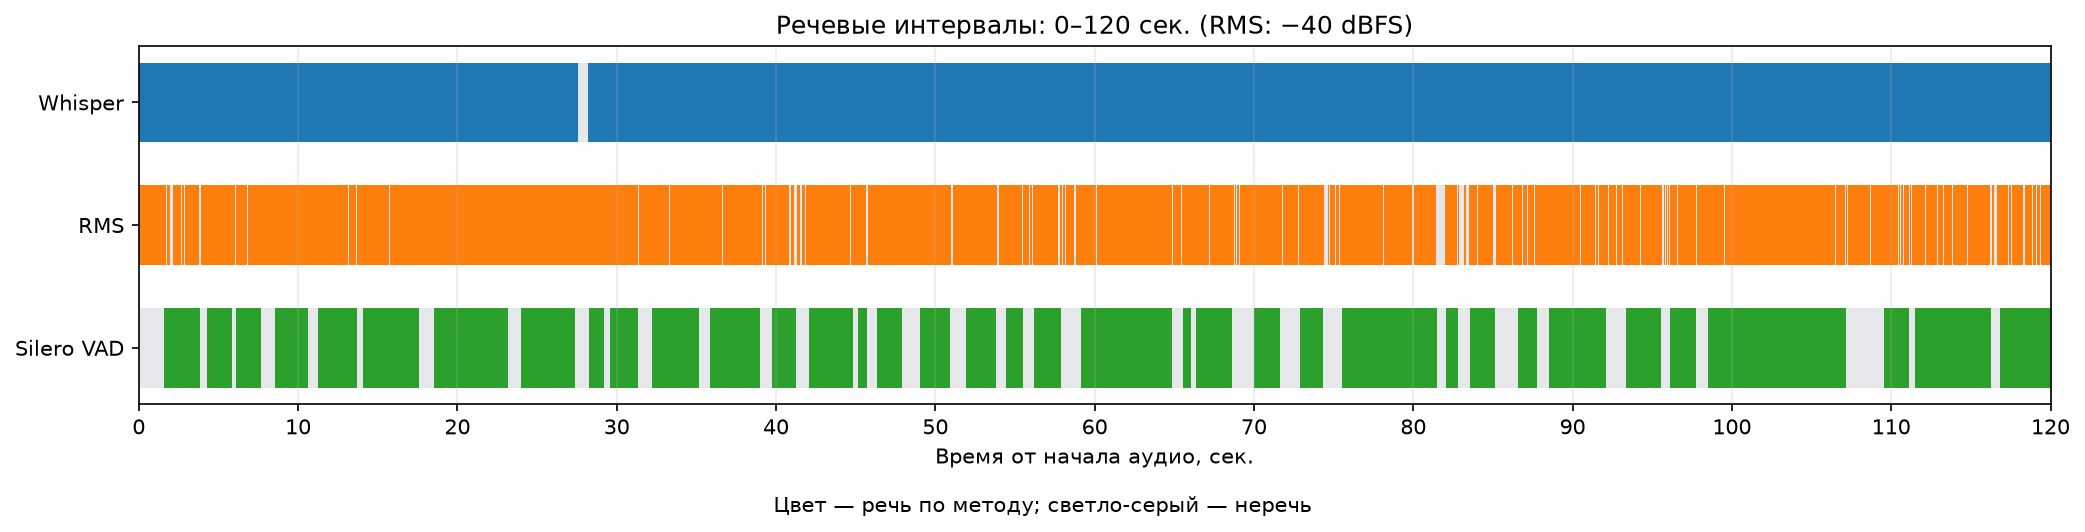

In [24]:
comparison_colors = {"Whisper": "tab:blue", "RMS": "tab:orange", "Silero VAD": "tab:green"}
comparison_methods = list(comparison_speech_intervals)

fig, ax = plt.subplots(figsize=(14, 3.5), dpi=150)
for row, method in zip([2, 1, 0], comparison_methods):
    intervals = comparison_speech_intervals[method]
    speech_bars = list(zip(intervals["start"], intervals["end"] - intervals["start"]))
    ax.broken_barh([(comparison_start, comparison_duration)], (row, 0.65), facecolors="#E5E7EB", edgecolors="none")
    ax.broken_barh(speech_bars, (row, 0.65), facecolors=comparison_colors[method], edgecolors="none")

ax.set_yticks([2.325, 1.325, 0.325], comparison_methods)
ax.set_xlim(comparison_start, comparison_end)
ax.set_xticks(np.arange(comparison_start, comparison_end + 1e-9, 10))
ax.set_xlabel("Время от начала аудио, сек.")
ax.set_title(f"Речевые интервалы: {comparison_start:.0f}–{comparison_end:.0f} сек. (RMS: −40 dBFS)")
ax.grid(axis="x", alpha=0.25)
fig.text(0.5, 0.01, "Цвет — речь по методу; светло-серый — неречь", ha="center")
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

### 9.3. Наблюдаемые расхождения на исходном видео

На первых 120 секундах Whisper отмечает почти весь участок как речь, оставляя только промежуток 27,6–28,2 секунды. RMS при −40 dBFS даёт много коротких провалов; Silero VAD выделяет более продолжительные неречевые участки и меньшую суммарную длительность речи. Это наблюдения для текущего видео и настроек.

Например, на участках **0,210–1,600** и **17,568–18,560 секунды** Whisper и RMS показывают речь, а Silero VAD — неречь. На **1,710–1,800 секунды** Whisper и Silero показывают речь, а RMS — неречь. Такие места удобно проверять прослушиванием.

Крупные сегменты Whisper могут включать внутренние паузы; RMS реагирует на уровень сигнала, а Silero VAD — на речевую активность с заданными порогами и минимальными длительностями. Большее или меньшее покрытие речи само по себе не определяет качество: вывод о том, какой метод лучше, требует эталонной разметки.

### 9.4. Исторический просмотр первого клипа KAIST

График использует абсолютное время исходного `room.wav` (280–340 с), хотя в CSV клипа `start/end` отсчитываются от начала 60-секундного входа. Цветные полосы означают речь. Каждая метрика в таблице вычислена по свежему предсказанию именно этого участка. Общий процент речи сам по себе не определяет качество: учитываются и пропуски, и ложные срабатывания.

Сохраняем первоначальную таблицу и график клипа с аудиосигналом. Блок использует определения из разделов 6–8; самостоятельный просмотр без WAV/MAT доступен в разделе 10.

,method,status,precision,recall,f1,iou,processing_s,x_realtime,fp_s,fn_s
0,spectral,ok,0.9902,0.9329,0.9607,0.9244,0.0323,1859.8481,0.4138,2.9956
1,rms,ok,0.9870,0.8272,0.9000,0.8183,0.0163,3676.6959,0.4876,7.7195
2,silero,ok,0.9727,0.9378,0.9549,0.9137,0.1217,493.1773,1.1777,2.7776
3,whisper,ok,0.8685,0.9137,0.8905,0.8026,6.2831,9.5494,6.1824,3.8542


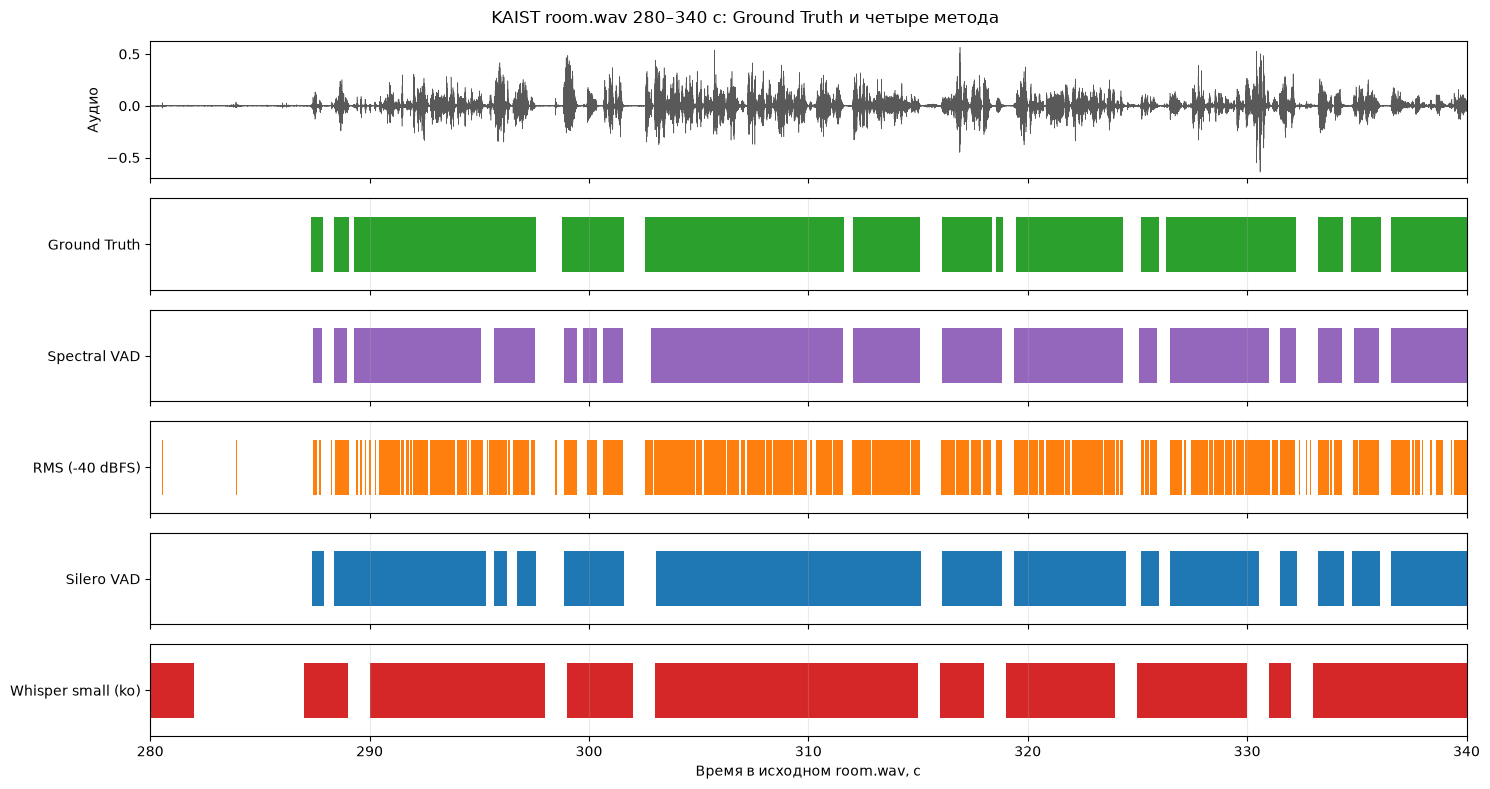

In [10]:
sv_saved_metrics = pd.read_csv(sv_results_dir / "room_280_340_metrics.csv", float_precision="round_trip")
sv_saved_experiment = json.loads((sv_results_dir / "experiment.json").read_text(encoding="utf-8"))
sv_saved_clip = sv_saved_experiment["protocol"]["four_method_clip"]
sv_saved_offset = sv_saved_clip["start"]
sv_saved_end = sv_saved_clip["end"]
sv_method_labels = {"spectral": "Spectral VAD", "rms": "RMS (-40 dBFS)", "silero": "Silero VAD", "whisper": "Whisper small (ko)"}
display(sv_saved_metrics[["method", "status", "precision", "recall", "f1", "iou", "processing_s", "x_realtime", "fp_s", "fn_s"]].round(4))
sv_saved_gt = pd.read_csv(sv_results_dir / "room_280_340_ground_truth_speech_intervals.csv", float_precision="round_trip")
sv_saved_predictions = {}
for method in sv_method_labels:
    if sv_saved_metrics.loc[sv_saved_metrics["method"] == method, "status"].iloc[0] == "ok":
        sv_saved_predictions[method] = pd.read_csv(sv_results_dir / f"room_280_340_{method}_speech_intervals.csv", float_precision="round_trip")
sv_plot_audio, _ = sv_load_recording("room", sv_saved_offset, sv_saved_end)
sv_figure, sv_axes = plt.subplots(6, 1, figsize=(15, 8), sharex=True, gridspec_kw={"height_ratios": [1.5, 1, 1, 1, 1, 1]})
sv_step = max(1, len(sv_plot_audio) // 50000)
sv_axes[0].plot(sv_saved_offset + np.arange(0, len(sv_plot_audio), sv_step) / sv_fs, sv_plot_audio[::sv_step], color="0.35", linewidth=0.4)
sv_axes[0].set_ylabel("Аудио")
sv_lanes = [("Ground Truth", sv_saved_gt, "tab:green")]
for method, color in zip(sv_method_labels, ["tab:purple", "tab:orange", "tab:blue", "tab:red"]):
    sv_lanes.append((sv_method_labels[method], sv_saved_predictions.get(method), color))
for axis, (label, intervals, color) in zip(sv_axes[1:], sv_lanes):
    if intervals is not None:
        bars = [(sv_saved_offset + start, end - start) for start, end in intervals.itertuples(index=False, name=None)]
        axis.broken_barh(bars, (0.2, 0.6), facecolors=color)
    else:
        axis.text(sv_saved_offset + 1, 0.5, "Не выполнен — см. experiment.json", va="center")
    axis.set_ylim(0, 1)
    axis.set_yticks([0.5], [label])
    axis.grid(axis="x", alpha=0.25)
sv_axes[-1].set_xlim(sv_saved_offset, sv_saved_end)
sv_axes[-1].set_xlabel("Время в исходном room.wav, с")
sv_figure.suptitle("KAIST room.wav 280–340 с: Ground Truth и четыре метода")
sv_figure.tight_layout()
sv_figure.savefig(sv_results_dir / "room_280_340_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

Сохраняем промежуточное заключение первого этапа. Полное сравнение четырёх методов приведено далее.

In [11]:
sv_saved_full = pd.read_csv(sv_results_dir / "spectral_recording_metrics.csv", float_precision="round_trip")
sv_saved_aggregate = pd.read_csv(sv_results_dir / "spectral_test_aggregate.csv", float_precision="round_trip")
sv_macro = sv_saved_aggregate.loc[sv_saved_aggregate["aggregation"] == "macro_three_test_recordings"].iloc[0]
sv_successful = sv_saved_metrics[sv_saved_metrics["status"] == "ok"].sort_values("f1", ascending=False)
sv_lines = [
    "### Промежуточный вывод по реально выполненному запуску",
    f"На трёх полных тестовых записях Spectral VAD получил macro F1 **{sv_macro['f1']:.4f}** и macro IoU **{sv_macro['iou']:.4f}**. Параметры после construction_site не менялись.",
]
for row in sv_successful.itertuples(index=False):
    sv_lines.append(f"- {sv_method_labels[row.method]} на room 280–340 с: F1 {row.f1:.4f}, IoU {row.iou:.4f}; ложная речь {row.fp_s:.3f} с, пропущенная речь {row.fn_s:.3f} с.")
for method, message in sv_saved_experiment["errors"].items():
    sv_lines.append(f"- {method} не выполнен: {message}")
sv_lines.append("Четырёхстороннее сравнение относится только к этому 60-секундному участку. Оно не устанавливает лучший метод для всего KAIST. Spectral VAD остаётся простым правилом на акустических признаках, которое может путать тональный шум с речью и пропускать шумную или негромкую речь. Для вывода об обобщающей способности нужны дополнительные записи и независимые дикторы.")
display(Markdown("\n\n".join(sv_lines)))

### Промежуточный вывод по реально выполненному запуску

На трёх полных тестовых записях Spectral VAD получил macro F1 **0.8393** и macro IoU **0.7352**. Параметры после construction_site не менялись.

- Spectral VAD на room 280–340 с: F1 0.9607, IoU 0.9244; ложная речь 0.414 с, пропущенная речь 2.996 с.

- Silero VAD на room 280–340 с: F1 0.9549, IoU 0.9137; ложная речь 1.178 с, пропущенная речь 2.778 с.

- RMS (-40 dBFS) на room 280–340 с: F1 0.9000, IoU 0.8183; ложная речь 0.488 с, пропущенная речь 7.720 с.

- Whisper small (ko) на room 280–340 с: F1 0.8905, IoU 0.8026; ложная речь 6.182 с, пропущенная речь 3.854 с.

Четырёхстороннее сравнение относится только к этому 60-секундному участку. Оно не устанавливает лучший метод для всего KAIST. Spectral VAD остаётся простым правилом на акустических признаках, которое может путать тональный шум с речью и пропускать шумную или негромкую речь. Для вывода об обобщающей способности нужны дополнительные записи и независимые дикторы.

<a id="kaist-final"></a>
## 10. Итоговое сравнение методов на KAIST VAD

**Самостоятельный раздел просмотра:** выполните все его ячейки по порядку в чистом ядре. Он читает только сохранённые CSV/JSON, не загружает модели, не использует CUDA, не меняет Ground Truth и не сохраняет файлы в results/.

Полные записи: room.wav, park.wav, bus_stop.wav, около 30 минут каждая. Параметры Spectral VAD подобраны на другой записи — construction_site.wav. Остальные конфигурации также зафиксированы. На KAIST Whisper использует language="ko"; русскоязычный эксперимент исходного видео остаётся отдельным.

Источники: results/kaist_full_comparison/ для 12 полных измерений и results/kaist_spectral_vad/ для настройки и отдельного клипа 280–340 с. Времена Spectral переиспользованы из первого этапа, остальные полные измерения выполнены позднее.

Класс «речь» оценивается по сэмплам 16 кГц без допуска на границах. Метрики лежат в диапазоне 0–1. Время включает обработку уже декодированного аудио и формирование интервалов; загрузка файлов, моделей и вычисление метрик исключены. RMS/Spectral/Silero выполнялись на CPU, Whisper — на RTX 3070. Это одиночные замеры, а не усреднённый benchmark.

### 10.1. Загрузка и проверка таблиц

Проверяем наличие файлов, SHA-256 из manifest, уникальность 12 полных измерений и четыре результата клипа. Macro-средние пересчитываются и сверяются с сохранённым CSV. Ни один расчёт ниже не подбирает параметры и не выполняет инференс.

In [2]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display

report_backend = next((p.resolve() for p in (Path.cwd(), Path.cwd() / "backend") if (p / "results/kaist_full_comparison/experiment.json").is_file()), None)
if report_backend is None:
    raise FileNotFoundError("Не найдены результаты KAIST. Запускайте из backend/ или корня проекта.")
report_full_dir = report_backend / "results/kaist_full_comparison"
report_spectral_dir = report_backend / "results/kaist_spectral_vad"
report_manifests = {}
report_checked_files = 0
for report_directory in [report_full_dir, report_spectral_dir]:
    report_manifest = json.loads((report_directory / "experiment.json").read_text(encoding="utf-8"))
    report_manifests[report_directory.name] = report_manifest
    for report_filename, report_description in report_manifest["csv_files"].items():
        report_path = report_directory / report_filename
        if not report_path.is_file():
            raise FileNotFoundError(report_path)
        assert hashlib.sha256(report_path.read_bytes()).hexdigest() == report_description["sha256"], report_filename
        report_table = pd.read_csv(report_path, float_precision="round_trip")
        assert len(report_table) == report_description["rows"], report_filename
        if "columns" in report_description:
            assert report_table.columns.tolist() == report_description["columns"], report_filename
        report_checked_files += 1
report_methods = ["spectral", "rms", "silero", "whisper"]
report_recordings = ["room", "park", "bus_stop"]
report_labels = {"spectral": "Spectral VAD", "rms": "RMS", "silero": "Silero", "whisper": "Whisper"}
report_colors = {"spectral": "tab:purple", "rms": "tab:orange", "silero": "tab:blue", "whisper": "tab:red"}
report_quality = ["precision", "recall", "f1", "iou"]
report_columns = [*report_quality, "processing_s"]
report_full = pd.read_csv(report_full_dir / "full_recording_metrics.csv", float_precision="round_trip")
report_clip = pd.read_csv(report_spectral_dir / "room_280_340_metrics.csv", float_precision="round_trip")
report_saved_macro = pd.read_csv(report_full_dir / "macro_averages.csv", float_precision="round_trip").set_index("method")
report_parameters = json.loads((report_full_dir / "parameters.json").read_text(encoding="utf-8"))
report_expected = {(m, r) for m in report_methods for r in report_recordings}
assert len(report_full) == 12
assert set(zip(report_full["method"], report_full["recording"])) == report_expected
assert not report_full.duplicated(["method", "recording"]).any()
assert len(report_clip) == 4 and set(report_clip["method"]) == set(report_methods)
for report_table in [report_full, report_clip]:
    assert report_table["status"].eq("ok").all()
    assert np.isfinite(report_table[report_columns].to_numpy()).all()
    assert report_table[report_quality].ge(0).all().all() and report_table[report_quality].le(1).all().all()
    assert report_table["processing_s"].gt(0).all()
    assert np.allclose(report_table["x_realtime"], report_table["duration_s"] / report_table["processing_s"], rtol=0, atol=1e-8)
assert report_full.groupby("recording")["duration_s"].nunique().eq(1).all()
report_macro = report_full.groupby("method")[report_columns].mean().reindex(report_methods)
np.testing.assert_allclose(report_macro.to_numpy(), report_saved_macro.loc[report_methods, report_columns].to_numpy(), rtol=0, atol=1e-12)
assert report_saved_macro.loc[report_methods, "recordings"].eq(3).all()
assert report_clip["source_offset_s"].eq(280).all() and report_clip["duration_s"].eq(60).all()
print(f"Проверено CSV: {report_checked_files}; полных измерений: {len(report_full)}; методов на клипе: {len(report_clip)}.")


def report_show(table):
    formats = {name: "{:.4f}".format for name in ["Precision", "Recall", "F1", "IoU"] if name in table.columns}
    if "Время, с" in table.columns:
        formats["Время, с"] = "{:.3f}".format
    display(HTML(table.to_html(index=False, formatters=formats, border=0, justify="left")))

Проверено CSV: 63; полных измерений: 12; методов на клипе: 4.


### 10.2. Проверка метрик по сохранённому Ground Truth

Границы переводятся обратно в индексы сэмплов. Пересечение упорядоченных списков даёт TP; FP, FN и TN вычисляются из общей длины и речевых интервалов. Пересчёт не требует WAV/MAT или массивов на всю запись. Проверяются 12 полных измерений и четыре результата клипа.

In [3]:
report_fs = 16000

def report_sample_intervals(table, total_samples):
    values = np.ceil(table[["start", "end"]].to_numpy() * report_fs - 1e-7).astype(np.int64)
    values = np.clip(values, 0, total_samples)
    assert (values[:, 1] > values[:, 0]).all()
    assert (values[1:, 0] >= values[:-1, 1]).all()
    return values.tolist()


def report_intersection(left, right):
    i = j = total = 0
    while i < len(left) and j < len(right):
        total += max(0, min(left[i][1], right[j][1]) - max(left[i][0], right[j][0]))
        if left[i][1] <= right[j][1]:
            i += 1
        else:
            j += 1
    return total


def report_verify_metrics(row, truth_file, prediction_file):
    total_samples = round(row.duration_s * report_fs)
    truth = report_sample_intervals(pd.read_csv(truth_file, float_precision="round_trip"), total_samples)
    predicted = report_sample_intervals(pd.read_csv(prediction_file, float_precision="round_trip"), total_samples)
    tp = report_intersection(truth, predicted)
    fp = sum(b - a for a, b in predicted) - tp
    fn = sum(b - a for a, b in truth) - tp
    tn = total_samples - tp - fp - fn
    assert [tp, fp, fn, tn] == [row.tp_samples, row.fp_samples, row.fn_samples, row.tn_samples]
    divide = lambda a, b: a / b if b else 0.0
    values = [divide(tp, tp + fp), divide(tp, tp + fn), divide(2 * tp, 2 * tp + fp + fn), divide(tp, tp + fp + fn)]
    np.testing.assert_allclose(values, [row.precision, row.recall, row.f1, row.iou], rtol=0, atol=1e-12)


for report_row in report_full.itertuples(index=False):
    report_verify_metrics(report_row, report_spectral_dir / f"{report_row.recording}_ground_truth_speech_intervals.csv", report_full_dir / f"{report_row.recording}_{report_row.method}_speech_intervals.csv")
for report_row in report_clip.itertuples(index=False):
    report_verify_metrics(report_row, report_spectral_dir / "room_280_340_ground_truth_speech_intervals.csv", report_spectral_dir / f"room_280_340_{report_row.method}_speech_intervals.csv")
print("Матрицы ошибок, Precision, Recall, F1 и IoU всех 16 измерений совпадают с CSV.")

Матрицы ошибок, Precision, Recall, F1 и IoU всех 16 измерений совпадают с CSV.


### 10.3. Полные тестовые записи: четыре метода

Каждая строка — полный WAV. Числа округлены только при отображении; CSV остаются без изменений. Клип 280–340 с не добавляется в эту таблицу отдельным наблюдением.

In [4]:
report_names = {"recording": "Запись", "method": "Метод", "precision": "Precision", "recall": "Recall", "f1": "F1", "iou": "IoU", "processing_s": "Время, с"}
report_full_ordered = report_full.set_index(["recording", "method"]).loc[pd.MultiIndex.from_product([report_recordings, report_methods])].reset_index()
report_full_view = report_full_ordered[["recording", "method", *report_columns]].copy()
report_full_view["recording"] += ".wav"
report_full_view["method"] = report_full_view["method"].map(report_labels)
report_show(report_full_view.rename(columns=report_names))

Запись,Метод,Precision,Recall,F1,IoU,"Время, с"
room.wav,Spectral VAD,0.9108,0.9543,0.9320,0.8727,1.041
room.wav,RMS,0.9360,0.7979,0.8614,0.7566,0.251
room.wav,Silero,0.9523,0.9521,0.9522,0.9088,2.463
room.wav,Whisper,0.3823,0.9927,0.5520,0.3812,60.635
park.wav,Spectral VAD,0.8957,0.8729,0.8842,0.7924,0.968
park.wav,RMS,0.2705,0.9993,0.4258,0.2705,0.238
park.wav,Silero,0.9267,0.9177,0.9222,0.8556,2.448
park.wav,Whisper,0.6789,0.9639,0.7966,0.6620,182.138
bus_stop.wav,Spectral VAD,0.9796,0.5466,0.7017,0.5405,0.958
bus_stop.wav,RMS,0.4013,1.0000,0.5728,0.4013,0.238


### 10.4. Macro-средние и зафиксированные параметры

Macro — арифметическое среднее каждой метрики по трём записям с одинаковыми весами. Средний F1 не равен F1 от средних Precision и Recall. Среднее время — среднее трёх одиночных замеров. Настроечная запись и отдельный клип в macro не включаются.

In [5]:
report_macro_view = report_macro.reset_index()
report_macro_view["method"] = report_macro_view["method"].map(report_labels)
report_show(report_macro_view.rename(columns=report_names))
report_sp_selected = report_parameters["spectral"]["selected_parameters"]
report_silero = report_parameters["silero"]
report_whisper = report_parameters["whisper"]
report_parameter_rows = [
    {"Метод": "Spectral VAD", "Параметры": f'STFT 16 кГц, Hann 25 мс / 10 мс, FFT 512, 200–4000 Гц; энергия max(-60 dBFS, Q20 + {report_sp_selected["energy_margin_db"]:g} дБ); энтропия ≤ {report_sp_selected["max_entropy"]:g}, плоскостность ≤ {report_sp_selected["max_flatness"]:g}; min speech {report_sp_selected["min_speech_ms"]} мс, max gap {report_sp_selected["max_gap_ms"]} мс'},
    {"Метод": "RMS", "Параметры": f'16 кГц; окно {report_parameters["rms"]["window_ms"]} мс; порог {report_parameters["rms"]["threshold_dbfs"]} dBFS; без сглаживания и нормализации по пику'},
    {"Метод": "Silero", "Параметры": f'v6 ONNX, CPU; пороги {report_silero["threshold"]}/{report_silero["neg_threshold"]}; min speech {report_silero["min_speech_duration_ms"]} мс, min silence {report_silero["min_silence_duration_ms"]} мс, padding {report_silero["speech_pad_ms"]} мс'},
    {"Метод": "Whisper", "Параметры": f'{report_whisper["model_size"]}, {report_whisper["device"]}, {report_whisper["compute_type"]}; language={report_whisper["transcribe_call_arguments"]["language"]}, vad_filter={report_whisper["transcribe_call_arguments"]["vad_filter"]}, beam_size={report_whisper["transcribe_call_arguments"]["beam_size"]}; остальные параметры — в parameters.json'},
]
report_show(pd.DataFrame(report_parameter_rows))

Метод,Precision,Recall,F1,IoU,"Время, с"
Spectral VAD,0.9287,0.7913,0.8393,0.7352,0.989
RMS,0.5359,0.9324,0.6200,0.4761,0.242
Silero,0.9392,0.9351,0.9372,0.8820,2.455
Whisper,0.6377,0.9808,0.7543,0.6283,131.683


Метод,Параметры
Spectral VAD,"STFT 16 кГц, Hann 25 мс / 10 мс, FFT 512, 200–4000 Гц; энергия max(-60 dBFS, Q20 + 12 дБ); энтропия ≤ 0.75, плоскостность ≤ 0.1; min speech 250 мс, max gap 250 мс"
RMS,16 кГц; окно 30 мс; порог -40 dBFS; без сглаживания и нормализации по пику
Silero,"v6 ONNX, CPU; пороги 0.5/0.35; min speech 250 мс, min silence 250 мс, padding 0 мс"
Whisper,"small, cuda, float16; language=ko, vad_filter=False, beam_size=5; остальные параметры — в parameters.json"


### 10.5. Сравнительные графики качества

Цвет каждого метода одинаков на всех рисунках. Первый рисунок показывает F1 по полным записям и macro F1. Precision и Recall показаны отдельно, чтобы различать ложные речевые решения и пропуски. Шкала качества начинается с 0.

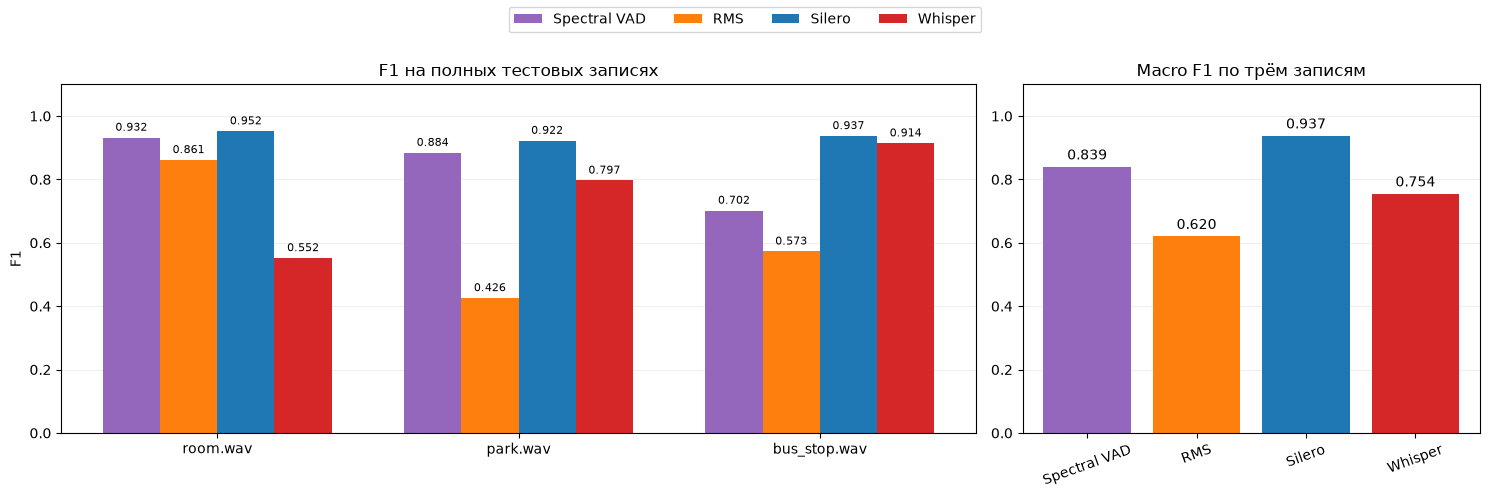

In [6]:
def report_grouped_plot(axis, table, metric, title, ylabel, logarithmic=False):
    matrix = table.pivot(index="recording", columns="method", values=metric).reindex(index=report_recordings, columns=report_methods)
    x = np.arange(len(report_recordings))
    for index, method in enumerate(report_methods):
        bars = axis.bar(x + (index - 1.5) * 0.19, matrix[method].to_numpy(), 0.19, label=report_labels[method], color=report_colors[method])
        axis.bar_label(bars, fmt="%.2f" if logarithmic else "%.3f", padding=3, fontsize=8)
    axis.set_xticks(x, [name + ".wav" for name in report_recordings])
    axis.set_title(title)
    axis.set_ylabel(ylabel)
    axis.grid(axis="y", alpha=0.2)
    axis.set_axisbelow(True)
    if logarithmic:
        axis.set_yscale("log")
        axis.set_ylim(matrix.to_numpy().min() * 0.5, matrix.to_numpy().max() * 3)
    else:
        axis.set_ylim(0, 1.10)


report_f1_figure, report_f1_axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2, 1]})
report_grouped_plot(report_f1_axes[0], report_full, "f1", "F1 на полных тестовых записях", "F1")
report_bars = report_f1_axes[1].bar([report_labels[m] for m in report_methods], report_macro["f1"], color=[report_colors[m] for m in report_methods])
report_f1_axes[1].bar_label(report_bars, fmt="%.3f", padding=3)
report_f1_axes[1].set_ylim(0, 1.10)
report_f1_axes[1].set_title("Macro F1 по трём записям")
report_f1_axes[1].tick_params(axis="x", labelrotation=20)
report_f1_axes[1].grid(axis="y", alpha=0.2)
report_f1_axes[1].set_axisbelow(True)
report_f1_figure.legend(*report_f1_axes[0].get_legend_handles_labels(), loc="upper center", ncol=4)
report_f1_figure.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

Precision и Recall на тех же трёх полных записях берутся из проверенной таблицы.

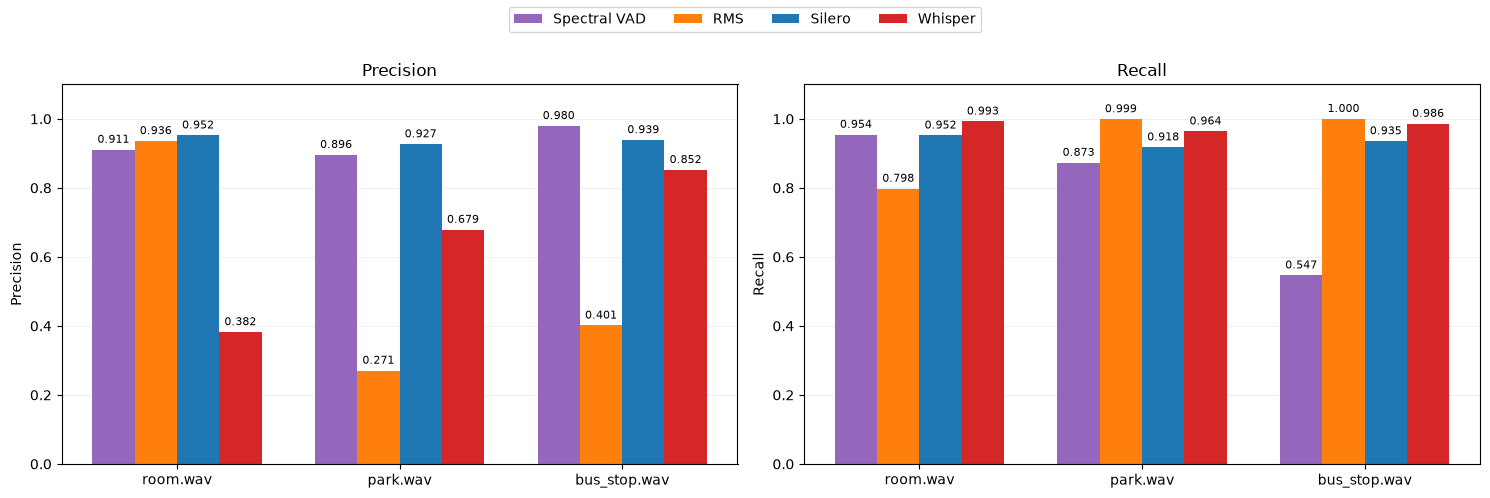

In [7]:
report_pr_figure, report_pr_axes = plt.subplots(1, 2, figsize=(15, 5))
report_grouped_plot(report_pr_axes[0], report_full, "precision", "Precision", "Precision")
report_grouped_plot(report_pr_axes[1], report_full, "recall", "Recall", "Recall")
report_pr_figure.legend(*report_pr_axes[0].get_legend_handles_labels(), loc="upper center", ncol=4)
report_pr_figure.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

### 10.6. Время обработки

Использована **логарифмическая шкала секунд**, чтобы одновременно видеть доли секунды и минуты. Подписи — реальные секунды. Различия CPU/GPU, одиночные замеры и переиспользование времени Spectral ограничивают интерпретацию скорости.

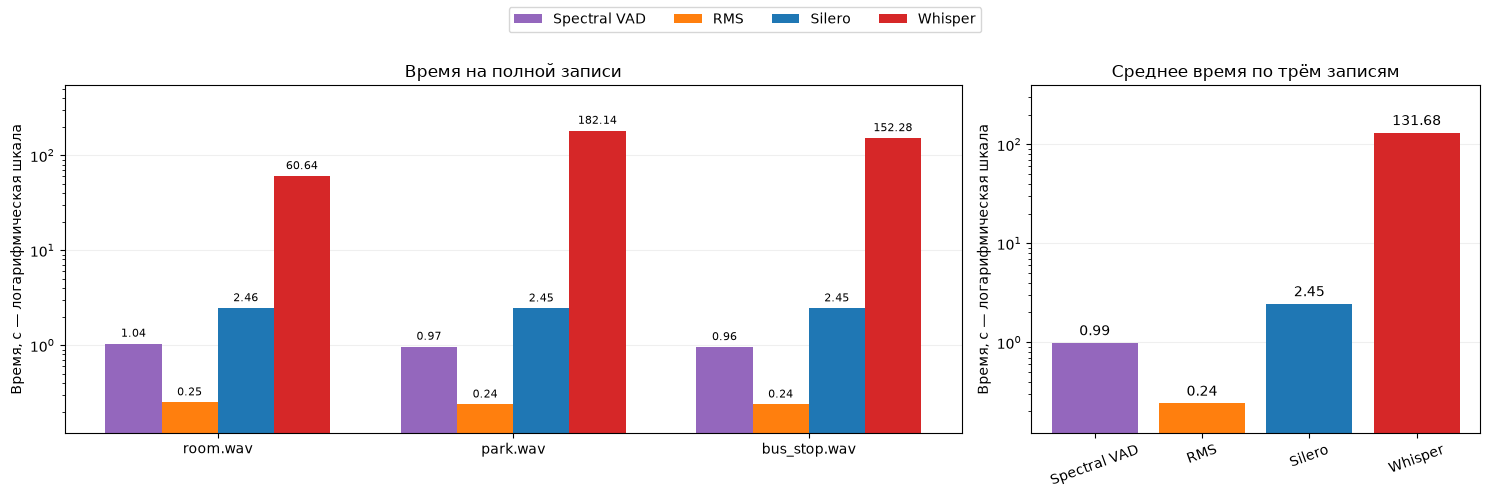

In [8]:
report_time_figure, report_time_axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2, 1]})
report_grouped_plot(report_time_axes[0], report_full, "processing_s", "Время на полной записи", "Время, с — логарифмическая шкала", logarithmic=True)
report_bars = report_time_axes[1].bar([report_labels[m] for m in report_methods], report_macro["processing_s"], color=[report_colors[m] for m in report_methods])
report_time_axes[1].bar_label(report_bars, fmt="%.2f", padding=3)
report_time_axes[1].set_yscale("log")
report_time_axes[1].set_ylim(report_macro["processing_s"].min() * 0.5, report_macro["processing_s"].max() * 3)
report_time_axes[1].set_title("Среднее время по трём записям")
report_time_axes[1].set_ylabel("Время, с — логарифмическая шкала")
report_time_axes[1].tick_params(axis="x", labelrotation=20)
report_time_axes[1].grid(axis="y", alpha=0.2)
report_time_axes[1].set_axisbelow(True)
report_time_figure.legend(*report_time_axes[0].get_legend_handles_labels(), loc="upper center", ncol=4)
report_time_figure.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

### 10.7. Отдельное сравнение: room.wav, 280–340 секунд

Это независимые запуски на одном 60-секундном входе, а не обрезка предсказаний с полной комнаты: контекст, оценка шума и ASR-сегменты могут отличаться. Клип не входит в macro. В CSV клипа start/end начинаются с 0; на дорожках прибавляется 280 секунд исходной записи.

Метод,Precision,Recall,F1,IoU,"Время, с"
Spectral VAD,0.9902,0.9329,0.9607,0.9244,0.032
RMS,0.9870,0.8272,0.9000,0.8183,0.016
Silero,0.9727,0.9378,0.9549,0.9137,0.122
Whisper,0.8685,0.9137,0.8905,0.8026,6.283


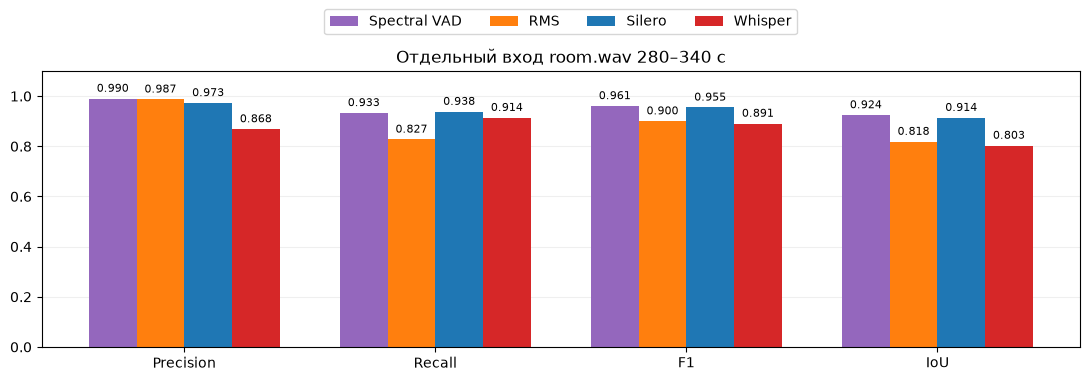

In [9]:
report_clip_ordered = report_clip.set_index("method").loc[report_methods]
report_clip_view = report_clip_ordered[report_columns].reset_index()
report_clip_view["method"] = report_clip_view["method"].map(report_labels)
report_show(report_clip_view.rename(columns=report_names))
report_clip_figure, report_clip_axis = plt.subplots(figsize=(11, 4))
report_x = np.arange(len(report_quality))
for report_index, report_method in enumerate(report_methods):
    report_values = report_clip_ordered.loc[report_method, report_quality].to_numpy(dtype=float)
    report_bars = report_clip_axis.bar(report_x + (report_index - 1.5) * 0.19, report_values, 0.19, label=report_labels[report_method], color=report_colors[report_method])
    report_clip_axis.bar_label(report_bars, fmt="%.3f", padding=3, fontsize=8)
report_clip_axis.set_xticks(report_x, ["Precision", "Recall", "F1", "IoU"])
report_clip_axis.set_ylim(0, 1.10)
report_clip_axis.set_title("Отдельный вход room.wav 280–340 с")
report_clip_axis.grid(axis="y", alpha=0.2)
report_clip_axis.set_axisbelow(True)
report_clip_axis.legend(loc="upper center", bbox_to_anchor=(0.5, 1.25), ncol=4)
report_clip_figure.tight_layout()
plt.show()

Дорожки показывают расхождения с эталоном. Загружаются только интервалы, без декодирования и моделей.

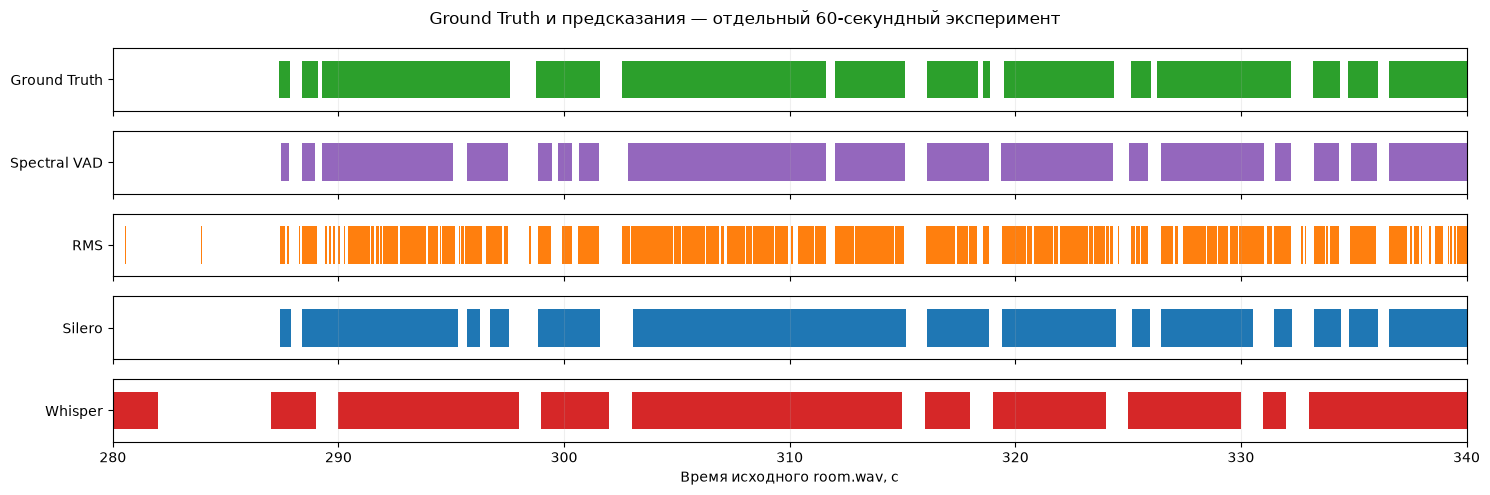

In [10]:
report_clip_gt = pd.read_csv(report_spectral_dir / "room_280_340_ground_truth_speech_intervals.csv", float_precision="round_trip")
report_lanes = [("Ground Truth", report_clip_gt, "tab:green")]
for report_method in report_methods:
    report_intervals = pd.read_csv(report_spectral_dir / f"room_280_340_{report_method}_speech_intervals.csv", float_precision="round_trip")
    report_lanes.append((report_labels[report_method], report_intervals, report_colors[report_method]))
report_timeline_figure, report_timeline_axes = plt.subplots(5, 1, figsize=(15, 5), sharex=True)
for report_axis, (report_label, report_intervals, report_color) in zip(report_timeline_axes, report_lanes):
    report_bars = [(280 + a, b - a) for a, b in report_intervals.itertuples(index=False, name=None)]
    report_axis.broken_barh(report_bars, (0.2, 0.6), facecolors=report_color)
    report_axis.set_ylim(0, 1)
    report_axis.set_yticks([0.5], [report_label])
    report_axis.grid(axis="x", alpha=0.2)
report_timeline_axes[-1].set_xlim(280, 340)
report_timeline_axes[-1].set_xlabel("Время исходного room.wav, с")
report_timeline_figure.suptitle("Ground Truth и предсказания — отдельный 60-секундный эксперимент")
report_timeline_figure.tight_layout()
plt.show()

### 10.8. Выводы: преимущества, недостатки и устойчивость Spectral VAD

Выводы формируются из проверенных CSV. Максимум на выбранном клипе не доказывает преимущество на полных записях. Для качества учитывается ограниченный объём и отсутствие независимого разделения по дикторам.

In [11]:
report_spectral_mean = report_macro.loc["spectral"]
report_best_method = report_macro["f1"].idxmax()
report_bus = report_full[(report_full["method"] == "spectral") & (report_full["recording"] == "bus_stop")].iloc[0]
report_spectral_f1 = report_full[report_full["method"] == "spectral"].set_index("recording")["f1"]
report_clip_best = report_clip_ordered["f1"].idxmax()
report_conclusions = [
    f"**Полные записи.** Максимальный macro F1 у {report_labels[report_best_method]}: {report_macro.loc[report_best_method, 'f1']:.4f}. Spectral VAD: macro Precision {report_spectral_mean['precision']:.4f}, Recall {report_spectral_mean['recall']:.4f}, F1 {report_spectral_mean['f1']:.4f}, IoU {report_spectral_mean['iou']:.4f}.",
    f"**Устойчивость Spectral.** F1 на room / park / bus_stop: {report_spectral_f1['room']:.4f} / {report_spectral_f1['park']:.4f} / {report_spectral_f1['bus_stop']:.4f}. На bus_stop Recall падает до {report_bus['recall']:.4f}; пропущено {report_bus['fn_s']:.3f} с размеченной речи. Переносимость фиксированного правила между условиями ограничена.",
    f"**Преимущества.** Интерпретируемые признаки, отсутствие нейросетевой модели и работа на CPU. Среднее измеренное время полной записи — {report_spectral_mean['processing_s']:.3f} с. Параметры после construction_site не менялись.",
    "**Недостатки.** Пороги энергии, энтропии и плоскостности не гарантируют отделение речи от тонального шума и тихой/шумной речи. Процентиль оценивается по всему текущему входу: это офлайн-метод, а не проверенный потоковый детектор.",
    f"**Короткий пример.** На отдельном клипе лучший F1 у {report_labels[report_clip_best]}: {report_clip_ordered.loc[report_clip_best, 'f1']:.4f}. Этот локальный результат не заменяет оценку трёх полных WAV.",
    "**Ограничения исследования.** Три тестовые записи и те же два диктора; нет оценки статистической значимости. Время измерено по одному запуску на CPU/GPU без загрузки моделей. Нужны новые условия, независимые дикторы и повторные замеры; параметры нельзя подбирать по этим тестовым метрикам.",
]
display(Markdown("\n\n".join(report_conclusions)))

**Полные записи.** Максимальный macro F1 у Silero: 0.9372. Spectral VAD: macro Precision 0.9287, Recall 0.7913, F1 0.8393, IoU 0.7352.

**Устойчивость Spectral.** F1 на room / park / bus_stop: 0.9320 / 0.8842 / 0.7017. На bus_stop Recall падает до 0.5466; пропущено 327.713 с размеченной речи. Переносимость фиксированного правила между условиями ограничена.

**Преимущества.** Интерпретируемые признаки, отсутствие нейросетевой модели и работа на CPU. Среднее измеренное время полной записи — 0.989 с. Параметры после construction_site не менялись.

**Недостатки.** Пороги энергии, энтропии и плоскостности не гарантируют отделение речи от тонального шума и тихой/шумной речи. Процентиль оценивается по всему текущему входу: это офлайн-метод, а не проверенный потоковый детектор.

**Короткий пример.** На отдельном клипе лучший F1 у Spectral VAD: 0.9607. Этот локальный результат не заменяет оценку трёх полных WAV.

**Ограничения исследования.** Три тестовые записи и те же два диктора; нет оценки статистической значимости. Время измерено по одному запуску на CPU/GPU без загрузки моделей. Нужны новые условия, независимые дикторы и повторные замеры; параметры нельзя подбирать по этим тестовым метрикам.